In [2]:
print("Colab is working")

Colab is working


In [3]:

%pip -q install yfinance

import yfinance as yf
import pandas as pd

print("EventEcho setup successful!")

Note: you may need to restart the kernel to use updated packages.
EventEcho setup successful!


In [4]:

start_date = "2016-01-01"
end_date = "2026-01-01"

# Reliance Industries
reliance = yf.download(
    "RELIANCE.NS",
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False
)

# Nifty 50 benchmark
nifty = yf.download(
    "^NSEI",
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False
)

print("Reliance shape:", reliance.shape)
print("Nifty shape:", nifty.shape)

print("\nReliance sample:")
display(reliance.head())

print("\nNifty sample:")
display(nifty.head())

Reliance shape: (2470, 6)
Nifty shape: (2464, 6)

Reliance sample:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,,
2016-01-01,218.997467,232.091934,232.903397,230.457565,230.823288,5416562
2016-01-04,214.672958,227.508835,231.737625,225.543015,229.726089,30170947
2016-01-05,216.797440,229.760376,230.869003,227.897430,228.651749,14946239
2016-01-06,222.631760,235.943558,237.360779,228.674606,230.320404,26759864
2016-01-07,218.544540,231.611908,234.983505,230.423279,233.394852,19739943



Nifty sample:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI
Date,,,,,,
2016-01-04,7791.299805,7791.299805,7937.549805,7781.100098,7924.549805,134700
2016-01-05,7784.649902,7784.649902,7831.200195,7763.250000,7828.399902,145200
2016-01-06,7741.000000,7741.000000,7800.950195,7721.200195,7788.049805,147100
2016-01-07,7568.299805,7568.299805,7674.950195,7556.600098,7673.350098,188900
2016-01-08,7601.350098,7601.350098,7634.100098,7581.049805,7611.649902,157400


In [5]:

print("Reliance columns:")
print(reliance.columns.tolist())

print("\nReliance missing values:")
print(reliance.isna().sum())

print("\nNifty missing values:")
print(nifty.isna().sum())

print("\nReliance date range:")
print(reliance.index.min(), "to", reliance.index.max())

print("\nNifty date range:")
print(nifty.index.min(), "to", nifty.index.max())

Reliance columns:
[('Adj Close', 'RELIANCE.NS'), ('Close', 'RELIANCE.NS'), ('High', 'RELIANCE.NS'), ('Low', 'RELIANCE.NS'), ('Open', 'RELIANCE.NS'), ('Volume', 'RELIANCE.NS')]

Reliance missing values:
Price      Ticker     
Adj Close  RELIANCE.NS    0
Close      RELIANCE.NS    0
High       RELIANCE.NS    0
Low        RELIANCE.NS    0
Open       RELIANCE.NS    0
Volume     RELIANCE.NS    0
dtype: int64

Nifty missing values:
Price      Ticker
Adj Close  ^NSEI     0
Close      ^NSEI     0
High       ^NSEI     0
Low        ^NSEI     0
Open       ^NSEI     0
Volume     ^NSEI     0
dtype: int64

Reliance date range:
2016-01-01 00:00:00 to 2025-12-31 00:00:00

Nifty date range:
2016-01-04 00:00:00 to 2025-12-31 00:00:00


# Step 2: Historical Price Data Validation

## Objective
Inspect the downloaded historical stock and benchmark data before calculating returns.

## Data Sources
- **Stock:** Reliance Industries (`RELIANCE.NS`)
- **Market Benchmark:** Nifty 50 (`^NSEI`)
- **Period:** January 2016 – December 2025

## Validation Checks
1. Verify the available columns and data types.
2. Inspect missing values and duplicate dates.
3. Confirm the historical date range.
4. Compare closing prices with adjusted closing prices.
5. Identify potential data-quality issues before calculating returns.

**Important:** Missing values and unusual price movements will be investigated rather than automatically removed.

In [6]:

# Inspect data structure
print("RELIANCE DATA")
print("Shape:", reliance.shape)
print("Columns:", reliance.columns.tolist())
print("\nData types:")
print(reliance.dtypes)

print("\nNIFTY 50 DATA")
print("Shape:", nifty.shape)
print("Columns:", nifty.columns.tolist())
print("\nData types:")
print(nifty.dtypes)

# Check duplicate dates
print("\nDuplicate dates:")
print("Reliance:", reliance.index.duplicated().sum())
print("Nifty:", nifty.index.duplicated().sum())

# Check missing values
print("\nMissing values — Reliance")
display(reliance.isna().sum())

print("\nMissing values — Nifty")
display(nifty.isna().sum())

# Inspect available date ranges
print("\nDate ranges:")
print("Reliance:", reliance.index.min(), "to", reliance.index.max())
print("Nifty:", nifty.index.min(), "to", nifty.index.max())

RELIANCE DATA
Shape: (2470, 6)
Columns: [('Adj Close', 'RELIANCE.NS'), ('Close', 'RELIANCE.NS'), ('High', 'RELIANCE.NS'), ('Low', 'RELIANCE.NS'), ('Open', 'RELIANCE.NS'), ('Volume', 'RELIANCE.NS')]

Data types:
Price      Ticker     
Adj Close  RELIANCE.NS    float64
Close      RELIANCE.NS    float64
High       RELIANCE.NS    float64
Low        RELIANCE.NS    float64
Open       RELIANCE.NS    float64
Volume     RELIANCE.NS      int64
dtype: object

NIFTY 50 DATA
Shape: (2464, 6)
Columns: [('Adj Close', '^NSEI'), ('Close', '^NSEI'), ('High', '^NSEI'), ('Low', '^NSEI'), ('Open', '^NSEI'), ('Volume', '^NSEI')]

Data types:
Price      Ticker
Adj Close  ^NSEI     float64
Close      ^NSEI     float64
High       ^NSEI     float64
Low        ^NSEI     float64
Open       ^NSEI     float64
Volume     ^NSEI       int64
dtype: object

Duplicate dates:
Reliance: 0
Nifty: 0

Missing values — Reliance


Price      Ticker     
Adj Close  RELIANCE.NS    0
Close      RELIANCE.NS    0
High       RELIANCE.NS    0
Low        RELIANCE.NS    0
Open       RELIANCE.NS    0
Volume     RELIANCE.NS    0
dtype: int64


Missing values — Nifty


Price      Ticker
Adj Close  ^NSEI     0
Close      ^NSEI     0
High       ^NSEI     0
Low        ^NSEI     0
Open       ^NSEI     0
Volume     ^NSEI     0
dtype: int64


Date ranges:
Reliance: 2016-01-01 00:00:00 to 2025-12-31 00:00:00
Nifty: 2016-01-04 00:00:00 to 2025-12-31 00:00:00


## Closing Price vs Adjusted Closing Price

The closing price represents the stock's market price at the end of a trading session. The adjusted closing price accounts for applicable corporate actions according to the data provider's adjustment methodology.

Corporate actions such as stock splits and dividends can affect historical price comparisons.

For this project, we will inspect both price series and document the selected return methodology before calculating abnormal returns.

**Decision rule:** Use a consistent, documented price series for stock and benchmark returns. Do not assume that adjusted prices are available or calculated identically across all data providers.

# Step 3: Daily Return Calculation

## Objective
Calculate daily returns for Reliance Industries and the Nifty 50 benchmark using historical price data.

## Methodology
Daily simple return is calculated as:

\[
R_t = \frac{P_t-P_{t-1}}{P_{t-1}}
\]

where:
- \(P_t\) is the price on the current trading day.
- \(P_{t-1}\) is the price on the previous available trading day.

Returns will be expressed as decimal values. For example, `0.03` represents a 3% return.

## Why This Matters
Stock returns measure the daily price change, while benchmark returns capture the broader market movement. Both are required for estimating expected returns and abnormal performance.

## Data Handling
- Prices will be sorted chronologically.
- Returns will be calculated separately for each instrument.
- The first return will be missing because no previous price is available.
- Missing prices will not be filled with artificial values.

The selected price series and its corporate-action adjustment methodology will be documented.


In [7]:

# Sort observations by date
reliance = reliance.sort_index()
nifty = nifty.sort_index()

# Inspect price columns before selecting the return series
print("Reliance columns:", reliance.columns.tolist())
print("Nifty columns:", nifty.columns.tolist())


Reliance columns: [('Adj Close', 'RELIANCE.NS'), ('Close', 'RELIANCE.NS'), ('High', 'RELIANCE.NS'), ('Low', 'RELIANCE.NS'), ('Open', 'RELIANCE.NS'), ('Volume', 'RELIANCE.NS')]
Nifty columns: [('Adj Close', '^NSEI'), ('Close', '^NSEI'), ('High', '^NSEI'), ('Low', '^NSEI'), ('Open', '^NSEI'), ('Volume', '^NSEI')]


# Step 3.1: Prepare Price Series and Calculate Daily Returns

## Objective
Extract the relevant price columns from the downloaded MultiIndex data and calculate daily returns.

## Methodology
- Use adjusted closing prices for the stock, where available and appropriate.
- Use the Nifty 50 closing-price series for the benchmark, while checking the provider's available adjustment fields.
- Sort observations chronologically.
- Calculate simple daily returns using percentage price changes.
- Preserve missing values rather than replacing them with zero.

The resulting return series will be used later to estimate the market model and calculate abnormal returns.


In [8]:

# Extract price series from MultiIndex columns
reliance_adj = reliance["Adj Close"]["RELIANCE.NS"].copy()
nifty_close = nifty["Close"]["^NSEI"].copy()

# Convert to clean, one-dimensional Series
reliance_adj.name = "RELIANCE"
nifty_close.name = "NIFTY50"

# Calculate daily simple returns
reliance_return = reliance_adj.pct_change(fill_method=None)
nifty_return = nifty_close.pct_change(fill_method=None)

reliance_return.name = "RELIANCE_RETURN"
nifty_return.name = "NIFTY50_RETURN"

# Align both return series on common dates
returns = pd.concat(
    [reliance_return, nifty_return],
    axis=1,
    join="inner"
)

# Remove rows where either return is unavailable
returns = returns.dropna()

print("Returns dataset shape:", returns.shape)
print("\nFirst 5 observations:")
display(returns.head())

print("\nLast 5 observations:")
display(returns.tail())

print("\nSummary statistics:")
display(returns.describe())


Returns dataset shape: (2463, 2)

First 5 observations:


,RELIANCE_RETURN,NIFTY50_RETURN
Date,,
2016-01-05,0.009896,-0.000854
2016-01-06,0.026911,-0.005607
2016-01-07,-0.018359,-0.022310
2016-01-08,0.012337,0.004367
2016-01-11,0.025201,-0.004933



Last 5 observations:


,RELIANCE_RETURN,NIFTY50_RETURN
Date,,
2025-12-24,-0.007958,-0.001339
2025-12-26,0.000642,-0.003818
2025-12-29,-0.008722,-0.003848
2025-12-30,-0.003753,-0.000125
2025-12-31,0.019873,0.007354



Summary statistics:


,RELIANCE_RETURN,NIFTY50_RETURN
count,2463.000000,2463.000000
mean,0.000946,0.000544
std,0.017054,0.010224
min,-0.131539,-0.129805
25%,-0.008291,-0.004167
50%,0.000655,0.000694
75%,0.009576,0.005808
max,0.147180,0.087632


## Interpretation of Daily Returns

The resulting dataset contains daily returns for Reliance Industries and the Nifty 50 on common dates.

- Positive returns indicate an increase in the selected price series.
- Negative returns indicate a decrease.
- Mean return represents the average daily return over the available sample.
- Standard deviation measures the variability of daily returns.
- The number of observations indicates how many common return dates remain after alignment.

**Limitation:** Daily returns alone do not establish whether a market event caused a stock-price movement. That requires the event-study methodology and appropriate statistical analysis.


# Step 4: Market Model Estimation

## Objective
Estimate the normal relationship between Reliance Industries' daily returns and Nifty 50 daily returns using linear regression.

## Model

\[
R_{i,t} = \alpha_i + \beta_i R_{m,t} + \epsilon_{i,t}
\]

Where:
- \(R_{i,t}\): Actual daily return of Reliance.
- \(R_{m,t}\): Daily return of the Nifty 50 benchmark.
- \(\alpha_i\): Estimated intercept.
- \(\beta_i\): Sensitivity to benchmark movements.
- \(\epsilon_{i,t}\): Residual return not explained by the model.

## Why This Model?
The market model accounts for broad market movements when estimating a stock's expected return. It provides the baseline required to calculate abnormal returns during event windows.

**Important:** The model must be estimated using an appropriate pre-event estimation window for each event. The full-sample model below is only an initial methodological demonstration.


In [9]:

import statsmodels.api as sm

# Define benchmark returns as the predictor
X = returns["NIFTY50_RETURN"]
X = sm.add_constant(X)

# Define Reliance returns as the target
y = returns["RELIANCE_RETURN"]

# Fit the initial market model
market_model = sm.OLS(y, X).fit()

print(market_model.summary())


                            OLS Regression Results                            
Dep. Variable:        RELIANCE_RETURN   R-squared:                       0.427
Model:                            OLS   Adj. R-squared:                  0.427
Method:                 Least Squares   F-statistic:                     1836.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          3.39e-300
Time:                        20:50:34   Log-Likelihood:                 7219.9
No. Observations:                2463   AIC:                        -1.444e+04
Df Residuals:                    2461   BIC:                        -1.442e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.0004      0.000      1.

# Step 4.1: Generate Model Predictions and Residuals

## Objective
Use the fitted Market Model to predict Reliance returns and calculate residuals.

## Methodology
- **Predicted return:** Return estimated by the fitted Market Model using Nifty's return.
- **Residual:** Actual Reliance return minus predicted Reliance return.

Residuals show how much of the observed return the fitted model does not explain.

## Important limitation
The model was fitted on the full dataset. Therefore, these residuals are preliminary diagnostics, **not the final event-study abnormal returns**. Final expected returns must be estimated using a pre-event estimation window for each event.

In [10]:
# Generate predicted returns from the fitted model
returns["PREDICTED_RELIANCE_RETURN"] = market_model.predict(X)

# Calculate residuals
returns["MODEL_RESIDUAL"] = (
    returns["RELIANCE_RETURN"]
    - returns["PREDICTED_RELIANCE_RETURN"]
)

print("First 5 observations:")
display(returns.head())

print("\nResidual summary:")
display(returns["MODEL_RESIDUAL"].describe())

print(
    "\nMean residual:",
    round(returns["MODEL_RESIDUAL"].mean(), 8)
)

First 5 observations:


,RELIANCE_RETURN,NIFTY50_RETURN,PREDICTED_RELIANCE_RETURN,MODEL_RESIDUAL
Date,,,,
2016-01-05,0.009896,-0.000854,-0.000578,0.010475
2016-01-06,0.026911,-0.005607,-0.005761,0.032672
2016-01-07,-0.018359,-0.022310,-0.023972,0.005613
2016-01-08,0.012337,0.004367,0.005114,0.007223
2016-01-11,0.025201,-0.004933,-0.005026,0.030227



Residual summary:


count    2.463000e+03
mean     1.983346e-18
std      1.290589e-02
min     -8.903420e-02
25%     -7.197998e-03
50%     -1.042229e-03
75%      6.317609e-03
max      1.146221e-01
Name: MODEL_RESIDUAL, dtype: float64


Mean residual: 0.0


# Step 4.3: Visualize Market Model Residuals

## Objective
Plot the model residuals over time to inspect unexplained return movements.

## What to look for
- Residuals fluctuating around zero.
- Periods with unusually large positive or negative residuals.
- Periods where residual volatility appears higher.

## Limitation
These are full-sample model residuals. They are useful for preliminary diagnostics, but they are not the final event-study abnormal returns.

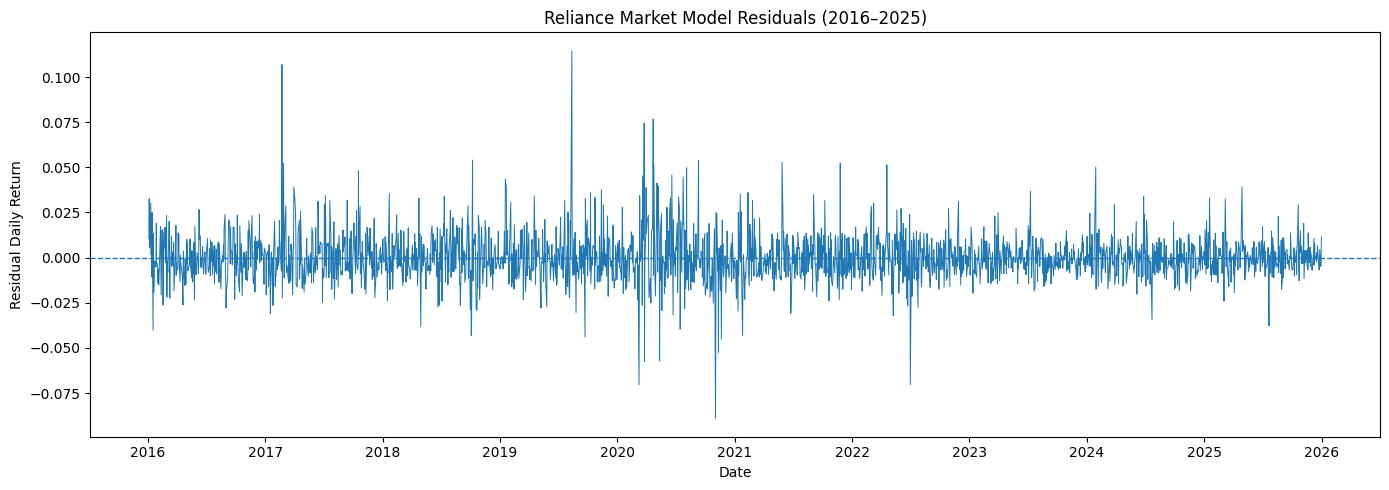

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    returns.index,
    returns["MODEL_RESIDUAL"],
    linewidth=0.7
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Reliance Market Model Residuals (2016–2025)")
plt.xlabel("Date")
plt.ylabel("Residual Daily Return")

plt.tight_layout()
plt.show()

===== OVERALL RESIDUAL DIAGNOSTICS =====
Observations: 2463
Mean: 0.0
Standard deviation: 0.012906
Median: -0.001042
Minimum: -0.089034
Maximum: 0.114622

===== EXTREME RESIDUALS (> 3 SD) =====
Count: 37
Date
2019-08-13    0.114622
2017-02-22    0.106946
2020-11-02   -0.089034
2020-04-22    0.076691
2020-03-25    0.074599
2022-07-01   -0.070428
2020-03-09   -0.070383
2020-03-26   -0.057600
2020-05-12   -0.057185
2018-10-08    0.054038

===== YEARLY RESIDUAL VOLATILITY =====
      Residual_SD  Mean_Absolute_Residual  Observations  Residual_SD_Pct
Date                                                                    
2016       0.0115                  0.0089           243           1.1504
2017       0.0147                  0.0102           248           1.4672
2018       0.0129                  0.0097           245           1.2865
2019       0.0148                  0.0100           241           1.4779
2020       0.0199                  0.0139           250           1.9931
2021      

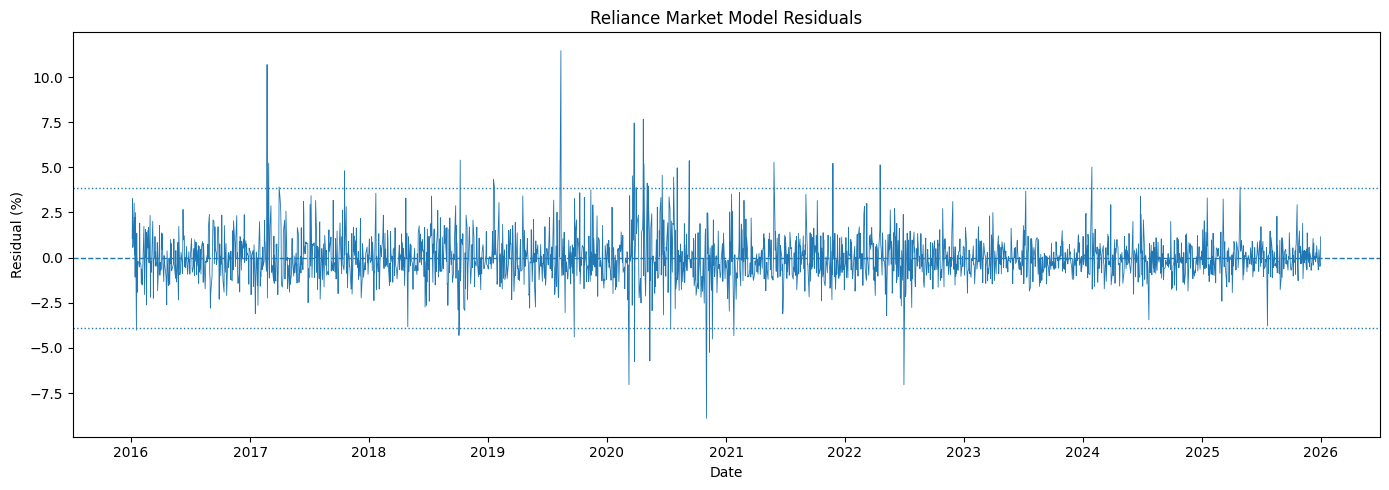

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Residual series
resid = returns["MODEL_RESIDUAL"].dropna().sort_index()

# 1. Overall diagnostics
print("===== OVERALL RESIDUAL DIAGNOSTICS =====")
print("Observations:", len(resid))
print("Mean:", round(resid.mean(), 6))
print("Standard deviation:", round(resid.std(), 6))
print("Median:", round(resid.median(), 6))
print("Minimum:", round(resid.min(), 6))
print("Maximum:", round(resid.max(), 6))

# 2. Extreme residual dates (threshold: +/- 3 standard deviations)
threshold = 3 * resid.std()
extremes = resid[resid.abs() > threshold]

print("\n===== EXTREME RESIDUALS (> 3 SD) =====")
if extremes.empty:
    print("No observations beyond +/- 3 standard deviations.")
else:
    print("Count:", len(extremes))
    print(extremes.sort_values(key=abs, ascending=False).head(10).to_string())

# 3. Residual volatility by calendar year
yearly = pd.DataFrame({
    "Residual_SD": resid.groupby(resid.index.year).std(),
    "Mean_Absolute_Residual": resid.abs().groupby(resid.index.year).mean(),
    "Observations": resid.groupby(resid.index.year).count()
})
yearly["Residual_SD_Pct"] = yearly["Residual_SD"] * 100

print("\n===== YEARLY RESIDUAL VOLATILITY =====")
print(yearly.round(4).to_string())

# 4. Rolling 20-trading-day residual volatility
rolling_sd = resid.rolling(20).std()

print("\n===== HIGHEST 20-DAY ROLLING VOLATILITY =====")
print(
    rolling_sd.nlargest(10).rename("Rolling_20D_SD").to_string()
)

# 5. Positive/negative residual proportions
print("\n===== RESIDUAL SIGN =====")
print("Positive (%):", round((resid > 0).mean() * 100, 2))
print("Negative (%):", round((resid < 0).mean() * 100, 2))
print("Near zero (%):", round((np.isclose(resid, 0)).mean() * 100, 2))

# 6. Plot with volatility band
plt.figure(figsize=(14, 5))
plt.plot(resid.index, resid * 100, linewidth=0.6)
plt.axhline(0, linestyle="--", linewidth=1)
plt.axhline(threshold * 100, linestyle=":", linewidth=1)
plt.axhline(-threshold * 100, linestyle=":", linewidth=1)
plt.title("Reliance Market Model Residuals")
plt.xlabel("Date")
plt.ylabel("Residual (%)")
plt.tight_layout()
plt.show()

# Step 5: Create the Event Master Dataset

## Objective
Create a structured dataset of historical events to study how Reliance reacts around corporate and economic announcements.

## Required fields
- `event_id`: Unique event identifier
- `event_date`: Verified announcement date
- `headline`: Short event description
- `category`: Event type
- `source_url`: Source used to verify the event
- `timing_confidence`: Confidence in announcement timing
- `episode_id`: Identifier for related events
- `overlap_flag`: Whether another event may overlap with the event window

## Methodology
Event dates must be verified from reliable sources. Announcement timing must be aligned to the appropriate trading session. Related announcements should be flagged so they are not incorrectly treated as independent events.

In [13]:
import pandas as pd

event_columns = [
    "event_id",
    "event_date",
    "event_time",
    "headline",
    "category",
    "source_name",
    "source_url",
    "timing_confidence",
    "episode_id",
    "overlap_flag",
    "notes"
]

events = pd.DataFrame(columns=event_columns)

print("Event master dataset initialized.")
print("Columns:", events.columns.tolist())
print("Number of events:", len(events))

display(events.head())

Event master dataset initialized.
Columns: ['event_id', 'event_date', 'event_time', 'headline', 'category', 'source_name', 'source_url', 'timing_confidence', 'episode_id', 'overlap_flag', 'notes']
Number of events: 0


,event_id,event_date,event_time,headline,category,source_name,source_url,timing_confidence,episode_id,overlap_flag,notes


In [14]:
def validate_events(events):
    required_fields = [
        "event_id",
        "event_date",
        "headline",
        "category",
        "source_name",
        "source_url"
    ]

    missing_columns = [
        col for col in required_fields
        if col not in events.columns
    ]

    if missing_columns:
        raise ValueError(f"Missing columns: {missing_columns}")

    if events.empty:
        print("No events added yet; schema validation only.")
        return

    if events["event_id"].isna().any():
        raise ValueError("Some events have missing event_id values.")

    if events["event_id"].duplicated().any():
        raise ValueError("Duplicate event_id values found.")

    parsed_dates = pd.to_datetime(
        events["event_date"],
        errors="coerce"
    )

    if parsed_dates.isna().any():
        raise ValueError("Invalid or missing event dates found.")

    for col in ["headline", "category", "source_name", "source_url"]:
        if events[col].isna().any():
            raise ValueError(f"Missing values found in {col}.")

    print("Event data validation passed.")

validate_events(events)

No events added yet; schema validation only.


# Step 6.1: Add Verified Seed Events

## Objective
Record a small set of historically documented events with source links.

## Methodology
- Preserve the original announcement date.
- Do not guess announcement times.
- Group related policy announcements using `episode_id`.
- Flag timing uncertainty for later trading-calendar alignment.
- Treat this as a pilot sample, not sufficient evidence for final statistical conclusions.

In [15]:
seed_events = [
    {
        "event_id": "EVT001",
        "event_date": "2016-11-08",
        "event_time": None,
        "headline": "India demonetisation announcement",
        "category": "Government Policy",
        "source_name": "Prime Minister of India",
        "source_url": "https://www.pmindia.gov.in/en/news_updates/prime-ministers-address-to-the-nation/?comment=disable",
        "timing_confidence": "high_date_time_not_in_master",
        "episode_id": "DEMONETISATION_2016",
        "overlap_flag": False,
        "notes": "Evening announcement; map to trading session using verified timing and calendar."
    },
    {
        "event_id": "EVT002",
        "event_date": "2020-03-24",
        "event_time": None,
        "headline": "Nationwide COVID-19 lockdown announced",
        "category": "Public Health / Government Policy",
        "source_name": "Press Information Bureau",
        "source_url": "https://www.pib.gov.in/PressReleasePage.aspx?PRID=1608009&lang=2&reg=48",
        "timing_confidence": "high_date_time_not_in_master",
        "episode_id": "COVID_LOCKDOWN_2020",
        "overlap_flag": False,
        "notes": "Announcement was made in the evening; expected next-session alignment must be checked."
    },
    {
        "event_id": "EVT003",
        "event_date": "2022-05-04",
        "event_time": None,
        "headline": "RBI raises repo rate by 40 basis points",
        "category": "Monetary Policy",
        "source_name": "Reserve Bank of India",
        "source_url": "https://www.rbi.org.in/commonman/Upload/English/PressRelease/PDFs/PR154MPC04052022.pdf",
        "timing_confidence": "date_verified_time_unverified",
        "episode_id": "RBI_TIGHTENING_2022",
        "overlap_flag": False,
        "notes": "Related to the broader 2022 monetary tightening cycle."
    },
    {
        "event_id": "EVT004",
        "event_date": "2022-06-08",
        "event_time": None,
        "headline": "RBI raises repo rate by 50 basis points",
        "category": "Monetary Policy",
        "source_name": "Press Information Bureau",
        "source_url": "https://www.pib.gov.in/PressReleaseIframePage.aspx?PRID=1832000&lang=2&reg=48",
        "timing_confidence": "date_verified_time_unverified",
        "episode_id": "RBI_TIGHTENING_2022",
        "overlap_flag": False,
        "notes": "Related to the broader 2022 monetary tightening cycle."
    },
    {
        "event_id": "EVT005",
        "event_date": "2022-08-05",
        "event_time": None,
        "headline": "RBI raises repo rate by 50 basis points",
        "category": "Monetary Policy",
        "source_name": "Reserve Bank of India",
        "source_url": "https://systemhealth.rbi.org.in/Scripts/BS_PressReleaseDisplay.aspx_prid=54148%281%29.html",
        "timing_confidence": "date_verified_time_unverified",
        "episode_id": "RBI_TIGHTENING_2022",
        "overlap_flag": False,
        "notes": "Related to the broader 2022 monetary tightening cycle."
    },
    {
        "event_id": "EVT006",
        "event_date": "2025-02-01",
        "event_time": None,
        "headline": "Union Budget 2025-26 presented",
        "category": "Government Policy / Budget",
        "source_name": "Press Information Bureau",
        "source_url": "https://www.pib.gov.in/Pressreleaseshare.aspx?PRID=2098352&lang=2&reg=48",
        "timing_confidence": "date_verified_session_check_required",
        "episode_id": "UNION_BUDGET_2025",
        "overlap_flag": False,
        "notes": "Budget day was a special Saturday trading session; verify exact event-time alignment before analysis."
    }
]

seed_df = pd.DataFrame(seed_events)

# Keep the existing schema and append the seed events
events = pd.concat(
    [events, seed_df.reindex(columns=event_columns)],
    ignore_index=True
)

events["event_date"] = pd.to_datetime(events["event_date"])

validate_events(events)

print("Total seed events:", len(events))
display(events[[
    "event_id",
    "event_date",
    "headline",
    "category",
    "episode_id",
    "timing_confidence"
]])

Event data validation passed.
Total seed events: 6


,event_id,event_date,headline,category,episode_id,timing_confidence
0,EVT001,2016-11-08,India demonetisation announcement,Government Policy,DEMONETISATION_2016,high_date_time_not_in_master
1,EVT002,2020-03-24,Nationwide COVID-19 lockdown announced,Public Health / Government Policy,COVID_LOCKDOWN_2020,high_date_time_not_in_master
2,EVT003,2022-05-04,RBI raises repo rate by 40 basis points,Monetary Policy,RBI_TIGHTENING_2022,date_verified_time_unverified
3,EVT004,2022-06-08,RBI raises repo rate by 50 basis points,Monetary Policy,RBI_TIGHTENING_2022,date_verified_time_unverified
4,EVT005,2022-08-05,RBI raises repo rate by 50 basis points,Monetary Policy,RBI_TIGHTENING_2022,date_verified_time_unverified
5,EVT006,2025-02-01,Union Budget 2025-26 presented,Government Policy / Budget,UNION_BUDGET_2025,date_verified_session_check_required


# Step 7: Align Events with Trading Sessions

## Objective
Map each event to the correct trading session using the historical stock and benchmark data.

## Methodology
- Before-market announcements: use the same trading session.
- After-market announcements: use the next trading session.
- Weekend announcements: use the next available session, unless a special trading session exists.
- Events with unverified announcement times must be flagged for manual review.

We will not assume that every event date maps to the same trading day. Incorrect alignment can produce misleading abnormal returns and CAR estimates.

In [16]:
# Step 7.1: Inspect event dates against available trading sessions

trading_dates = pd.DatetimeIndex(returns.index).normalize().unique().sort_values()

def inspect_event_date(event_date):
    event_date = pd.Timestamp(event_date).normalize()

    previous_dates = trading_dates[trading_dates < event_date]
    same_date = trading_dates[trading_dates == event_date]
    next_dates = trading_dates[trading_dates > event_date]

    return {
        "event_date": event_date.date(),
        "date_is_trading_session": len(same_date) > 0,
        "previous_session": (
            previous_dates[-1].date() if len(previous_dates) else None
        ),
        "next_session": (
            next_dates[0].date() if len(next_dates) else None
        )
    }

alignment_check = pd.DataFrame(
    [
        {
            "event_id": row["event_id"],
            "headline": row["headline"],
            **inspect_event_date(row["event_date"])
        }
        for _, row in events.iterrows()
    ]
)

display(alignment_check)

,event_id,headline,event_date,date_is_trading_session,previous_session,next_session
0,EVT001,India demonetisation announcement,2016-11-08,True,2016-11-07,2016-11-09
1,EVT002,Nationwide COVID-19 lockdown announced,2020-03-24,True,2020-03-23,2020-03-25
2,EVT003,RBI raises repo rate by 40 basis points,2022-05-04,True,2022-05-02,2022-05-05
3,EVT004,RBI raises repo rate by 50 basis points,2022-06-08,True,2022-06-07,2022-06-09
4,EVT005,RBI raises repo rate by 50 basis points,2022-08-05,True,2022-08-04,2022-08-08
5,EVT006,Union Budget 2025-26 presented,2025-02-01,True,2025-01-31,2025-02-03


# Step 8: Assign Effective Event Dates

## Objective
Determine which trading session should be treated as event day (Day 0).

## Rules
- Evening demonetisation announcement: next trading session.
- Evening COVID-19 lockdown announcement: next trading session.
- RBI rate announcements: retain as pending until announcement timing is verified.
- Union Budget 2025: retain the special Saturday trading session, subject to confirming the announcement timing relative to market hours.

The original announcement date will remain unchanged for traceability. The effective event date will be stored separately.

In [17]:
# Step 8.1: Create a separate effective event date

events["event_date"] = pd.to_datetime(events["event_date"])

events["effective_event_date"] = pd.NaT
events["alignment_status"] = "Pending timing verification"

# Verified evening announcements: use the next trading session
after_close_events = ["EVT001", "EVT002"]

for event_id in after_close_events:
    original_date = events.loc[
        events["event_id"] == event_id, "event_date"
    ].iloc[0]

    future_sessions = trading_dates[
        trading_dates > original_date.normalize()
    ]

    if len(future_sessions) > 0:
        events.loc[
            events["event_id"] == event_id,
            "effective_event_date"
        ] = future_sessions[0]

        events.loc[
            events["event_id"] == event_id,
            "alignment_status"
        ] = "Next trading session: after-close announcement"

# Union Budget: retain the special trading date for now
events.loc[
    events["event_id"] == "EVT006",
    "effective_event_date"
] = pd.Timestamp("2025-02-01")

events.loc[
    events["event_id"] == "EVT006",
    "alignment_status"
] = "Provisional: special-session timing check required"

display(events[[
    "event_id",
    "event_date",
    "effective_event_date",
    "headline",
    "alignment_status"
]])

,event_id,event_date,effective_event_date,headline,alignment_status
0,EVT001,2016-11-08,2016-11-09,India demonetisation announcement,Next trading session: after-close announcement
1,EVT002,2020-03-24,2020-03-25,Nationwide COVID-19 lockdown announced,Next trading session: after-close announcement
2,EVT003,2022-05-04,NaT,RBI raises repo rate by 40 basis points,Pending timing verification
3,EVT004,2022-06-08,NaT,RBI raises repo rate by 50 basis points,Pending timing verification
4,EVT005,2022-08-05,NaT,RBI raises repo rate by 50 basis points,Pending timing verification
5,EVT006,2025-02-01,2025-02-01,Union Budget 2025-26 presented,Provisional: special-session timing check requ...


# Step 9: Verify Announcement Timing

## Objective
Verify whether each announcement occurred before, during, or after the relevant market session.

## Why this matters
Event day (Day 0) determines which returns are included in the event window. Incorrect timing can shift the measured reaction by one trading day.

## Verification rules
- Before market open: same trading session.
- During market hours: same session, while noting possible anticipation.
- After market close: next trading session.
- Special trading sessions: use the actual session calendar and verified announcement time.
- Unverified timing: leave the event pending rather than guessing.

In [18]:
# Step 9.1: Create a timing-verification checklist

timing_review = events[[
    "event_id",
    "event_date",
    "headline",
    "source_name",
    "source_url",
    "effective_event_date",
    "alignment_status"
]].copy()

timing_review["announcement_time_verified"] = False
timing_review["market_session"] = "Needs verification"
timing_review["verified_effective_date"] = pd.NaT
timing_review["verification_notes"] = ""

display(timing_review)

,event_id,event_date,headline,source_name,source_url,effective_event_date,alignment_status,announcement_time_verified,market_session,verified_effective_date,verification_notes
0,EVT001,2016-11-08,India demonetisation announcement,Prime Minister of India,https://www.pmindia.gov.in/en/news_updates/pri...,2016-11-09,Next trading session: after-close announcement,False,Needs verification,NaT,
1,EVT002,2020-03-24,Nationwide COVID-19 lockdown announced,Press Information Bureau,https://www.pib.gov.in/PressReleasePage.aspx?P...,2020-03-25,Next trading session: after-close announcement,False,Needs verification,NaT,
2,EVT003,2022-05-04,RBI raises repo rate by 40 basis points,Reserve Bank of India,https://www.rbi.org.in/commonman/Upload/Englis...,NaT,Pending timing verification,False,Needs verification,NaT,
3,EVT004,2022-06-08,RBI raises repo rate by 50 basis points,Press Information Bureau,https://www.pib.gov.in/PressReleaseIframePage....,NaT,Pending timing verification,False,Needs verification,NaT,
4,EVT005,2022-08-05,RBI raises repo rate by 50 basis points,Reserve Bank of India,https://systemhealth.rbi.org.in/Scripts/BS_Pre...,NaT,Pending timing verification,False,Needs verification,NaT,
5,EVT006,2025-02-01,Union Budget 2025-26 presented,Press Information Bureau,https://www.pib.gov.in/Pressreleaseshare.aspx?...,2025-02-01,Provisional: special-session timing check requ...,False,Needs verification,NaT,


In [19]:
# Record the timing review and verified event-session alignment

verified_alignment = {
    "EVT001": {
        "date": "2016-11-09",
        "session": "Next trading session",
        "note": "Official source confirms evening announcement on Nov 8."
    },
    "EVT002": {
        "date": "2020-03-25",
        "session": "Next trading session",
        "note": "PM address was at 20:57 IST on Mar 24."
    },
    "EVT003": {
        "date": "2022-05-04",
        "session": "During market hours",
        "note": "RBI surprise statement was around 14:00 IST."
    },
    "EVT004": {
        "date": "2022-06-08",
        "session": "During market hours",
        "note": "RBI policy announcement occurred during the morning."
    },
    "EVT005": {
        "date": "2022-08-05",
        "session": "During market hours",
        "note": "RBI Governor's policy statement was scheduled for 10:00 IST."
    },
    "EVT006": {
        "date": "2025-02-01",
        "session": "Special trading session",
        "note": "Budget was presented during the NSE special Saturday session."
    }
}

for event_id, info in verified_alignment.items():
    mask = events["event_id"] == event_id

    events.loc[mask, "effective_event_date"] = pd.Timestamp(info["date"])
    events.loc[mask, "alignment_status"] = "Verified: " + info["session"]

    timing_review.loc[
        timing_review["event_id"] == event_id,
        "announcement_time_verified"
    ] = True

    timing_review.loc[
        timing_review["event_id"] == event_id,
        "market_session"
    ] = info["session"]

    timing_review.loc[
        timing_review["event_id"] == event_id,
        "verified_effective_date"
    ] = pd.Timestamp(info["date"])

    timing_review.loc[
        timing_review["event_id"] == event_id,
        "verification_notes"
    ] = info["note"]

print("Effective dates assigned:", events["effective_event_date"].notna().sum())
display(events[[
    "event_id",
    "event_date",
    "effective_event_date",
    "alignment_status"
]])

display(timing_review[[
    "event_id",
    "announcement_time_verified",
    "market_session",
    "verified_effective_date",
    "verification_notes"
]])

Effective dates assigned: 6


,event_id,event_date,effective_event_date,alignment_status
0,EVT001,2016-11-08,2016-11-09,Verified: Next trading session
1,EVT002,2020-03-24,2020-03-25,Verified: Next trading session
2,EVT003,2022-05-04,2022-05-04,Verified: During market hours
3,EVT004,2022-06-08,2022-06-08,Verified: During market hours
4,EVT005,2022-08-05,2022-08-05,Verified: During market hours
5,EVT006,2025-02-01,2025-02-01,Verified: Special trading session


,event_id,announcement_time_verified,market_session,verified_effective_date,verification_notes
0,EVT001,True,Next trading session,2016-11-09,Official source confirms evening announcement ...
1,EVT002,True,Next trading session,2020-03-25,PM address was at 20:57 IST on Mar 24.
2,EVT003,True,During market hours,2022-05-04,RBI surprise statement was around 14:00 IST.
3,EVT004,True,During market hours,2022-06-08,RBI policy announcement occurred during the mo...
4,EVT005,True,During market hours,2022-08-05,RBI Governor's policy statement was scheduled ...
5,EVT006,True,Special trading session,2025-02-01,Budget was presented during the NSE special Sa...


# Step 10: Identify Related and Overlapping Events

## Objective
Identify events that belong to the same broader episode and determine whether their event windows overlap.

## Methodology
- Use `episode_id` to group related events.
- Use the effective event date as Day 0.
- Initially evaluate a [-5, +5] trading-session window.
- Flag overlapping windows separately from events that are merely related.
- Do not treat related events as independent evidence without considering their shared context.

In [20]:
# Step 10.1: Build event windows using actual trading-session positions

event_window_size = 5

# Ensure all effective dates are aligned to the available returns index
trading_dates = pd.DatetimeIndex(returns.index).normalize().unique().sort_values()

window_records = []

for _, event in events.iterrows():
    effective_date = pd.Timestamp(event["effective_event_date"]).normalize()

    matching_positions = [
        i for i, date in enumerate(trading_dates)
        if date == effective_date
    ]

    if not matching_positions:
        window_records.append({
            "event_id": event["event_id"],
            "effective_event_date": effective_date,
            "window_start": pd.NaT,
            "window_end": pd.NaT,
            "window_status": "Effective date not found in returns index"
        })
        continue

    pos = matching_positions[0]
    start_pos = max(0, pos - event_window_size)
    end_pos = min(len(trading_dates) - 1, pos + event_window_size)

    window_records.append({
        "event_id": event["event_id"],
        "effective_event_date": effective_date,
        "window_start": trading_dates[start_pos],
        "window_end": trading_dates[end_pos],
        "window_status": "OK" if (
            pos - event_window_size >= 0
            and pos + event_window_size < len(trading_dates)
        ) else "Window truncated at data boundary"
    })

event_windows = pd.DataFrame(window_records)

display(event_windows)

,event_id,effective_event_date,window_start,window_end,window_status
0,EVT001,2016-11-09,2016-11-02,2016-11-17,OK
1,EVT002,2020-03-25,2020-03-18,2020-04-01,OK
2,EVT003,2022-05-04,2022-04-26,2022-05-11,OK
3,EVT004,2022-06-08,2022-06-01,2022-06-15,OK
4,EVT005,2022-08-05,2022-07-29,2022-08-16,OK
5,EVT006,2025-02-01,2025-01-27,2025-02-07,OK


In [21]:
# Compare every event window with every other event window

overlap_records = []

valid_windows = event_windows.dropna(
    subset=["window_start", "window_end"]
).reset_index(drop=True)

for i in range(len(valid_windows)):
    for j in range(i + 1, len(valid_windows)):
        event_a = valid_windows.iloc[i]
        event_b = valid_windows.iloc[j]

        overlaps = (
            event_a["window_start"] <= event_b["window_end"]
            and event_b["window_start"] <= event_a["window_end"]
        )

        overlap_records.append({
            "event_1": event_a["event_id"],
            "event_2": event_b["event_id"],
            "event_1_window": (
                f'{event_a["window_start"].date()} to '
                f'{event_a["window_end"].date()}'
            ),
            "event_2_window": (
                f'{event_b["window_start"].date()} to '
                f'{event_b["window_end"].date()}'
            ),
            "windows_overlap": overlaps
        })

overlap_analysis = pd.DataFrame(overlap_records)

display(overlap_analysis)

print(
    "Number of overlapping event pairs:",
    int(overlap_analysis["windows_overlap"].sum())
)

,event_1,event_2,event_1_window,event_2_window,windows_overlap
0,EVT001,EVT002,2016-11-02 to 2016-11-17,2020-03-18 to 2020-04-01,False
1,EVT001,EVT003,2016-11-02 to 2016-11-17,2022-04-26 to 2022-05-11,False
2,EVT001,EVT004,2016-11-02 to 2016-11-17,2022-06-01 to 2022-06-15,False
3,EVT001,EVT005,2016-11-02 to 2016-11-17,2022-07-29 to 2022-08-16,False
4,EVT001,EVT006,2016-11-02 to 2016-11-17,2025-01-27 to 2025-02-07,False
5,EVT002,EVT003,2020-03-18 to 2020-04-01,2022-04-26 to 2022-05-11,False
6,EVT002,EVT004,2020-03-18 to 2020-04-01,2022-06-01 to 2022-06-15,False
7,EVT002,EVT005,2020-03-18 to 2020-04-01,2022-07-29 to 2022-08-16,False
8,EVT002,EVT006,2020-03-18 to 2020-04-01,2025-01-27 to 2025-02-07,False
9,EVT003,EVT004,2022-04-26 to 2022-05-11,2022-06-01 to 2022-06-15,False


Number of overlapping event pairs: 0


In [22]:
# Update overlap flags in the event master

overlapping_event_ids = set()

for _, row in overlap_analysis.iterrows():
    if row["windows_overlap"]:
        overlapping_event_ids.add(row["event_1"])
        overlapping_event_ids.add(row["event_2"])

events["overlap_flag"] = events["event_id"].isin(
    overlapping_event_ids
)

# Store related-episode information separately
events["episode_id"] = events["episode_id"].fillna("UNASSIGNED")

events["episode_related_flag"] = events["episode_id"].duplicated(
    keep=False
)

print("Events with overlapping windows:", events["overlap_flag"].sum())
print("Events in shared episodes:", events["episode_related_flag"].sum())

display(events[[
    "event_id",
    "headline",
    "episode_id",
    "overlap_flag",
    "episode_related_flag"
]])

Events with overlapping windows: 0
Events in shared episodes: 3


,event_id,headline,episode_id,overlap_flag,episode_related_flag
0,EVT001,India demonetisation announcement,DEMONETISATION_2016,False,False
1,EVT002,Nationwide COVID-19 lockdown announced,COVID_LOCKDOWN_2020,False,False
2,EVT003,RBI raises repo rate by 40 basis points,RBI_TIGHTENING_2022,False,True
3,EVT004,RBI raises repo rate by 50 basis points,RBI_TIGHTENING_2022,False,True
4,EVT005,RBI raises repo rate by 50 basis points,RBI_TIGHTENING_2022,False,True
5,EVT006,Union Budget 2025-26 presented,UNION_BUDGET_2025,False,False


# Step 11: Define the Estimation Window

## Objective
Prepare pre-event historical returns for estimating the market model separately for each event.

## Model
R(i,t) = alpha(i) + beta(i) × R(m,t) + error(i,t)

Where:
- R(i,t): stock return
- R(m,t): market benchmark return
- alpha(i), beta(i): parameters estimated using pre-event observations

## Window definitions
- Estimation window: Day −120 to Day −21
- Buffer period: Day −20 to Day −6
- Event windows: Day −1 to +1, Day −3 to +3, and Day −5 to +5

Only the estimation window will be used to fit the market model. Event-window returns will be used later to calculate abnormal returns.

In [23]:
# Step 11.1: Create pre-event estimation samples

estimation_length = 100
buffer_length = 20

# Align return dates and event dates consistently
returns = returns.copy()
returns.index = pd.DatetimeIndex(returns.index).normalize()
returns = returns.sort_index()

trading_dates = pd.DatetimeIndex(
    returns.index.unique()
).sort_values()

estimation_samples = {}

for _, event in events.iterrows():
    event_id = event["event_id"]
    event_date = pd.Timestamp(
        event["effective_event_date"]
    ).normalize()

    event_positions = [
        i for i, date in enumerate(trading_dates)
        if date == event_date
    ]

    if not event_positions:
        print(f"{event_id}: effective event date not found")
        continue

    event_pos = event_positions[0]

    # Day -21 through Day -120, inclusive: 100 observations
    estimation_end_pos = event_pos - buffer_length
    estimation_start_pos = estimation_end_pos - estimation_length + 1

    if estimation_start_pos < 0:
        print(f"{event_id}: insufficient pre-event history")
        continue

    estimation_dates = trading_dates[
        estimation_start_pos:estimation_end_pos + 1
    ]

    sample = returns.loc[estimation_dates, [
        "RELIANCE_RETURN",
        "NIFTY50_RETURN"
    ]].dropna()

    estimation_samples[event_id] = sample

    print(
        f"{event_id}: {len(sample)} estimation observations | "
        f"{sample.index.min().date()} to {sample.index.max().date()}"
    )

EVT001: 100 estimation observations | 2016-05-16 to 2016-10-07
EVT002: 100 estimation observations | 2019-09-30 to 2020-02-25
EVT003: 100 estimation observations | 2021-11-09 to 2022-04-01
EVT004: 100 estimation observations | 2021-12-15 to 2022-05-11
EVT005: 100 estimation observations | 2022-02-14 to 2022-07-08
EVT006: 100 estimation observations | 2024-08-13 to 2025-01-06


# Step 12: Fit Event-Specific Market Models

## Objective
Estimate the relationship between Reliance returns and Nifty 50 returns separately for each event.

## Method
For each event, fit an OLS regression using only its 100-observation estimation sample:

R(i,t) = alpha(i) + beta(i) × R(m,t) + error(i,t)

The estimated coefficients will be used to predict expected stock returns during the event window.

## Important
The event window is not used to fit the model. This prevents event-period returns from influencing the expected-return estimates.

In [24]:
# Step 12.1: Fit a separate market model for each event

import statsmodels.api as sm

event_models = {}
model_results = []

for event_id, sample in estimation_samples.items():

    # Market return is the explanatory variable
    X_est = sm.add_constant(sample["NIFTY50_RETURN"])

    # Stock return is the dependent variable
    y_est = sample["RELIANCE_RETURN"]

    model = sm.OLS(y_est, X_est).fit()

    event_models[event_id] = model

    model_results.append({
        "event_id": event_id,
        "observations": int(model.nobs),
        "alpha_daily": model.params["const"],
        "beta": model.params["NIFTY50_RETURN"],
        "r_squared": model.rsquared,
        "alpha_p_value": model.pvalues["const"],
        "beta_p_value": model.pvalues["NIFTY50_RETURN"]
    })

model_summary = pd.DataFrame(model_results)

display(
    model_summary.style.format({
        "alpha_daily": "{:.5%}",
        "beta": "{:.4f}",
        "r_squared": "{:.4f}",
        "alpha_p_value": "{:.4f}",
        "beta_p_value": "{:.4f}"
    })
)

,event_id,observations,alpha_daily,beta,r_squared,alpha_p_value,beta_p_value
0,EVT001,100,0.03352%,0.7040,0.2165,0.7444,0.0000
1,EVT002,100,0.05684%,1.1179,0.3295,0.6396,0.0000
2,EVT003,100,0.09372%,1.1600,0.6106,0.4270,0.0000
3,EVT004,100,0.10963%,1.0620,0.5612,0.3641,0.0000
4,EVT005,100,0.09196%,1.0623,0.4524,0.5602,0.0000
5,EVT006,100,-0.13746%,1.2131,0.6259,0.0729,0.0000


# Step 13: Calculate Expected Returns and Abnormal Returns

## Objective
Measure how Reliance performed relative to the return predicted by its event-specific market model.

## Formulas

Expected return:

E(R(i,t)) = estimated alpha(i) + estimated beta(i) × R(m,t)

Abnormal return:

AR(i,t) = R(i,t) − E(R(i,t))

Abnormal returns will be calculated for each event from Day −5 to Day +5. Positive AR indicates performance above the model prediction; negative AR indicates performance below it.

These are abnormal returns relative to the fitted market model, not proof that the event caused the stock movement.

In [25]:
# Step 13.1: Calculate event-window expected returns and abnormal returns

event_study_rows = []

for _, event in events.iterrows():

    event_id = event["event_id"]
    event_date = pd.Timestamp(
        event["effective_event_date"]
    ).normalize()

    if event_id not in event_models:
        continue

    # Find Day 0 in the trading calendar
    positions = [
        i for i, date in enumerate(trading_dates)
        if date == event_date
    ]

    if not positions:
        print(f"{event_id}: event date not found")
        continue

    event_pos = positions[0]
    model = event_models[event_id]

    # Extract Day -5 through Day +5
    start_pos = event_pos - 5
    end_pos = event_pos + 5

    window_dates = trading_dates[start_pos:end_pos + 1]

    event_data = returns.loc[
        window_dates,
        ["RELIANCE_RETURN", "NIFTY50_RETURN"]
    ].copy()

    # Use only the model fitted for this event
    expected = (
        model.params["const"]
        + model.params["NIFTY50_RETURN"]
        * event_data["NIFTY50_RETURN"]
    )

    event_data["EXPECTED_RETURN"] = expected
    event_data["ABNORMAL_RETURN"] = (
        event_data["RELIANCE_RETURN"]
        - event_data["EXPECTED_RETURN"]
    )

    event_data["event_id"] = event_id
    event_data["event_date"] = event_date
    event_data["event_day"] = range(-5, 6)

    event_study_rows.append(
        event_data.reset_index(names="trading_date")
    )

event_study = pd.concat(
    event_study_rows,
    ignore_index=True
)

print("Event-window observations:", len(event_study))
display(event_study.head(11))

Event-window observations: 66


,trading_date,RELIANCE_RETURN,NIFTY50_RETURN,EXPECTED_RETURN,ABNORMAL_RETURN,event_id,event_date,event_day
0,2016-11-02,-0.025928,-0.013013,-0.008825,-0.017102,EVT001,2016-11-09,-5
1,2016-11-03,0.000195,-0.003412,-0.002067,0.002262,EVT001,2016-11-09,-4
2,2016-11-04,-0.017970,-0.006034,-0.003913,-0.014057,EVT001,2016-11-09,-3
3,2016-11-07,-0.004376,0.007506,0.005619,-0.009995,EVT001,2016-11-09,-2
4,2016-11-08,0.002347,0.005472,0.004188,-0.001840,EVT001,2016-11-09,-1
5,2016-11-09,0.001096,-0.013057,-0.008856,0.009953,EVT001,2016-11-09,0
6,2016-11-10,0.005773,0.011118,0.008162,-0.002389,EVT001,2016-11-09,1
7,2016-11-11,-0.008561,-0.026913,-0.018611,0.010050,EVT001,2016-11-09,2
8,2016-11-15,-0.016321,-0.022643,-0.015605,-0.000717,EVT001,2016-11-09,3
9,2016-11-16,0.001167,0.000388,0.000609,0.000558,EVT001,2016-11-09,4


# Step 14: Calculate Cumulative Abnormal Returns (CAR)

## Objective
Aggregate abnormal returns over multiple event windows.

## Formula

CAR[a,b] = sum of abnormal returns from Day a to Day b.

We will calculate:
- CAR(-1,+1): immediate reaction
- CAR(-3,+3): short-term reaction
- CAR(-5,+5): wider reaction

## Interpretation
CAR measures the accumulated abnormal returns over the selected sessions. Comparing windows shows whether the result is sensitive to the window length. CAR alone does not establish causality or statistical significance.

In [26]:
# Step 14.1: Calculate CAR for each event and event window

event_window_specs = {
    "CAR_-1_+1": (-1, 1),
    "CAR_-3_+3": (-3, 3),
    "CAR_-5_+5": (-5, 5)
}

car_rows = []

for event_id, group in event_study.groupby("event_id"):

    for car_name, (lower_day, upper_day) in event_window_specs.items():

        selected = group[
            group["event_day"].between(lower_day, upper_day)
        ]

        car_rows.append({
            "event_id": event_id,
            "event_date": group["event_date"].iloc[0],
            "window": car_name,
            "sessions_included": len(selected),
            "CAR": selected["ABNORMAL_RETURN"].sum()
        })

car_results = pd.DataFrame(car_rows)

display(
    car_results.style.format({
        "CAR": "{:.2%}"
    })
)

,event_id,event_date,window,sessions_included,CAR
0,EVT001,2016-11-09 00:00:00,CAR_-1_+1,3,0.57%
1,EVT001,2016-11-09 00:00:00,CAR_-3_+3,7,-0.90%
2,EVT001,2016-11-09 00:00:00,CAR_-5_+5,11,-2.98%
3,EVT002,2020-03-25 00:00:00,CAR_-1_+1,3,5.22%
4,EVT002,2020-03-25 00:00:00,CAR_-3_+3,7,12.05%
5,EVT002,2020-03-25 00:00:00,CAR_-5_+5,11,16.87%
6,EVT003,2022-05-04 00:00:00,CAR_-1_+1,3,-2.86%
7,EVT003,2022-05-04 00:00:00,CAR_-3_+3,7,-5.25%
8,EVT003,2022-05-04 00:00:00,CAR_-5_+5,11,-4.93%
9,EVT004,2022-06-08 00:00:00,CAR_-1_+1,3,1.42%


# Step 15: Statistical Significance of CAR

## Objective
Evaluate whether the observed cumulative abnormal returns are large relative to the stock's historical residual volatility.

## Method
For each event window, calculate an approximate t-statistic:

t = CAR / (sigma × sqrt(L))

Where:
- CAR = cumulative abnormal return
- sigma = residual standard deviation from the event-specific estimation model
- L = number of trading sessions in the event window

We will calculate two-sided p-values using the estimation model's residual degrees of freedom.

## Limitations
This is a basic diagnostic test. It assumes that estimation-period residual volatility is representative of the event period and does not fully account for serial dependence, event-induced volatility, or all estimation-parameter uncertainty. Results will be treated as preliminary, not definitive evidence.

In [27]:
# Step 15.1: Approximate CAR significance tests

from scipy import stats
import numpy as np

significance_rows = []

for _, row in car_results.iterrows():
    event_id = row["event_id"]
    window = row["window"]
    car = row["CAR"]

    model = event_models[event_id]
    residual_std = np.sqrt(model.mse_resid)

    sessions = int(row["sessions_included"])
    standard_error = residual_std * np.sqrt(sessions)

    t_stat = car / standard_error
    degrees_freedom = int(model.df_resid)

    p_value = 2 * stats.t.sf(
        abs(t_stat),
        df=degrees_freedom
    )

    significance_rows.append({
        "event_id": event_id,
        "event_date": row["event_date"],
        "window": window,
        "CAR": car,
        "approx_standard_error": standard_error,
        "t_statistic": t_stat,
        "p_value": p_value,
        "significant_at_5pct": p_value < 0.05
    })

car_significance = pd.DataFrame(significance_rows)

display(
    car_significance.style.format({
        "CAR": "{:.2%}",
        "approx_standard_error": "{:.2%}",
        "t_statistic": "{:.3f}",
        "p_value": "{:.4f}"
    })
)

,event_id,event_date,window,CAR,approx_standard_error,t_statistic,p_value,significant_at_5pct
0,EVT001,2016-11-09 00:00:00,CAR_-1_+1,0.57%,1.76%,0.326,0.7453,False
1,EVT001,2016-11-09 00:00:00,CAR_-3_+3,-0.90%,2.68%,-0.335,0.7382,False
2,EVT001,2016-11-09 00:00:00,CAR_-5_+5,-2.98%,3.36%,-0.885,0.3781,False
3,EVT002,2020-03-25 00:00:00,CAR_-1_+1,5.22%,2.09%,2.492,0.0144,True
4,EVT002,2020-03-25 00:00:00,CAR_-3_+3,12.05%,3.20%,3.766,0.0003,True
5,EVT002,2020-03-25 00:00:00,CAR_-5_+5,16.87%,4.01%,4.206,0.0001,True
6,EVT003,2022-05-04 00:00:00,CAR_-1_+1,-2.86%,2.03%,-1.405,0.1630,False
7,EVT003,2022-05-04 00:00:00,CAR_-3_+3,-5.25%,3.11%,-1.689,0.0943,False
8,EVT003,2022-05-04 00:00:00,CAR_-5_+5,-4.93%,3.90%,-1.264,0.2091,False
9,EVT004,2022-06-08 00:00:00,CAR_-1_+1,1.42%,2.08%,0.685,0.4951,False


## Step 15: Preliminary Results and Interpretation

The approximate CAR significance test produced the following observations:

- **COVID-19 lockdown (EVT002):** CAR was positive across all three event windows and statistically significant at the 5% level under the preliminary test.
- **Demonetisation (EVT001):** CAR changed from positive in the short window to negative in the wider window. None of the three windows was statistically significant.
- **RBI rate announcements (EVT003–EVT005):** None of the CAR estimates was statistically significant at the 5% level.
- **Union Budget 2025 (EVT006):** CAR estimates were small, and none was statistically significant at the 5% level.

### Limitations

These results are preliminary. The test uses a simplified standard-error formula and does not fully account for event-induced volatility, serial dependence, or estimation uncertainty. Testing multiple events and windows also increases the risk of false positives.

**Conclusion:** The observed CARs describe stock performance relative to the estimated market model. They do not establish that an event caused the observed movement or that the pattern can be used profitably for trading. Confidence intervals, multiple-testing correction, and robustness checks are required before drawing stronger conclusions.

# Step 16: Confidence Intervals and Multiple-Testing Correction

## Objective
Quantify uncertainty around CAR estimates and control false-positive risk when testing multiple event windows.

## Method
1. Calculate approximate 95% confidence intervals for each CAR.
2. Apply the Holm correction to all 18 p-values.
3. Compare the original p-values with adjusted p-values.

## Interpretation
- A confidence interval containing zero means the data do not rule out a zero CAR at the 5% level under the chosen approximation.
- A Holm-adjusted p-value below 0.05 indicates significance after correcting for multiple tests.

## Limitations
The confidence intervals and p-values inherit the assumptions of the preliminary standard-error method. They are not definitive event-study inference.


In [28]:
from statsmodels.stats.multitest import multipletests
from scipy import stats

results_inference = car_significance.copy()

# Use the residual degrees of freedom from each event-specific model
df_by_event = {
    event_id: int(model.df_resid)
    for event_id, model in event_models.items()
}

results_inference["critical_value"] = results_inference[
    "event_id"
].map(
    lambda event_id: stats.t.ppf(
        0.975, df=df_by_event[event_id]
    )
)

# Approximate 95% confidence intervals
results_inference["CI_lower_95"] = (
    results_inference["CAR"]
    - results_inference["critical_value"]
    * results_inference["approx_standard_error"]
)

results_inference["CI_upper_95"] = (
    results_inference["CAR"]
    + results_inference["critical_value"]
    * results_inference["approx_standard_error"]
)

# Holm correction across all 18 event-window tests
reject_holm, p_holm, _, _ = multipletests(
    results_inference["p_value"],
    alpha=0.05,
    method="holm"
)

results_inference["p_value_holm"] = p_holm
results_inference["significant_after_holm"] = reject_holm

display(
    results_inference[[
        "event_id",
        "window",
        "CAR",
        "CI_lower_95",
        "CI_upper_95",
        "p_value",
        "p_value_holm",
        "significant_after_holm"
    ]].style.format({
        "CAR": "{:.2%}",
        "CI_lower_95": "{:.2%}",
        "CI_upper_95": "{:.2%}",
        "p_value": "{:.4f}",
        "p_value_holm": "{:.4f}"
    })
)

,event_id,window,CAR,CI_lower_95,CI_upper_95,p_value,p_value_holm,significant_after_holm
0,EVT001,CAR_-1_+1,0.57%,-2.91%,4.06%,0.7453,1.0000,False
1,EVT001,CAR_-3_+3,-0.90%,-6.22%,4.43%,0.7382,1.0000,False
2,EVT001,CAR_-5_+5,-2.98%,-9.65%,3.70%,0.3781,1.0000,False
3,EVT002,CAR_-1_+1,5.22%,1.06%,9.38%,0.0144,0.2300,False
4,EVT002,CAR_-3_+3,12.05%,5.70%,18.40%,0.0003,0.0048,True
5,EVT002,CAR_-5_+5,16.87%,8.91%,24.83%,0.0001,0.0010,True
6,EVT003,CAR_-1_+1,-2.86%,-6.90%,1.18%,0.1630,1.0000,False
7,EVT003,CAR_-3_+3,-5.25%,-11.42%,0.92%,0.0943,1.0000,False
8,EVT003,CAR_-5_+5,-4.93%,-12.66%,2.81%,0.2091,1.0000,False
9,EVT004,CAR_-1_+1,1.42%,-2.70%,5.55%,0.4951,1.0000,False


## Step 16: Results and Interpretation

### Key Findings

- **COVID-19 lockdown (EVT002):** The CAR was positive for all three windows. However, after Holm correction, only the \([-3,+3]\) window (adjusted \(p=0.0048\)) and the \([-5,+5]\) window (adjusted \(p=0.0010\)) remained statistically significant.
- **Demonetisation (EVT001):** None of the three CAR estimates was statistically significant after multiple-testing correction.
- **RBI announcements (EVT003–EVT005):** No event window remained statistically significant after correction.
- **Union Budget 2025 (EVT006):** No event window was statistically significant after correction.

### Interpretation

The confidence intervals for the two significant COVID-19 windows excluded zero under the approximate method. The \([-1,+1]\) window did not remain significant after Holm correction, despite its unadjusted \(p\)-value being 0.0144.

### Limitations

These findings are based on only six selected events and a simplified standard-error method. The COVID-19 period also involved substantial market volatility and potential confounding factors. Statistical significance does not establish causation or prove that a profitable trading strategy exists.

**Conclusion:** Multiple-testing correction changes the interpretation of the initial results. The findings are useful for demonstrating the event-study framework, but stronger conclusions require a larger, systematically selected event sample and more robust statistical tests.

# Step 17: Visualizing Event Reactions

## Objective
Visualize abnormal returns around each event and compare cumulative abnormal returns across event windows.

## Plots
1. Event-time abnormal returns from Day −5 to Day +5 for each event.
2. CAR comparison across the \([-1,+1]\), \([-3,+3]\), and \([-5,+5]\) windows.

## Interpretation
The plots help identify the direction, magnitude, and timing of abnormal performance. Visual patterns are descriptive and should be interpreted alongside statistical uncertainty.

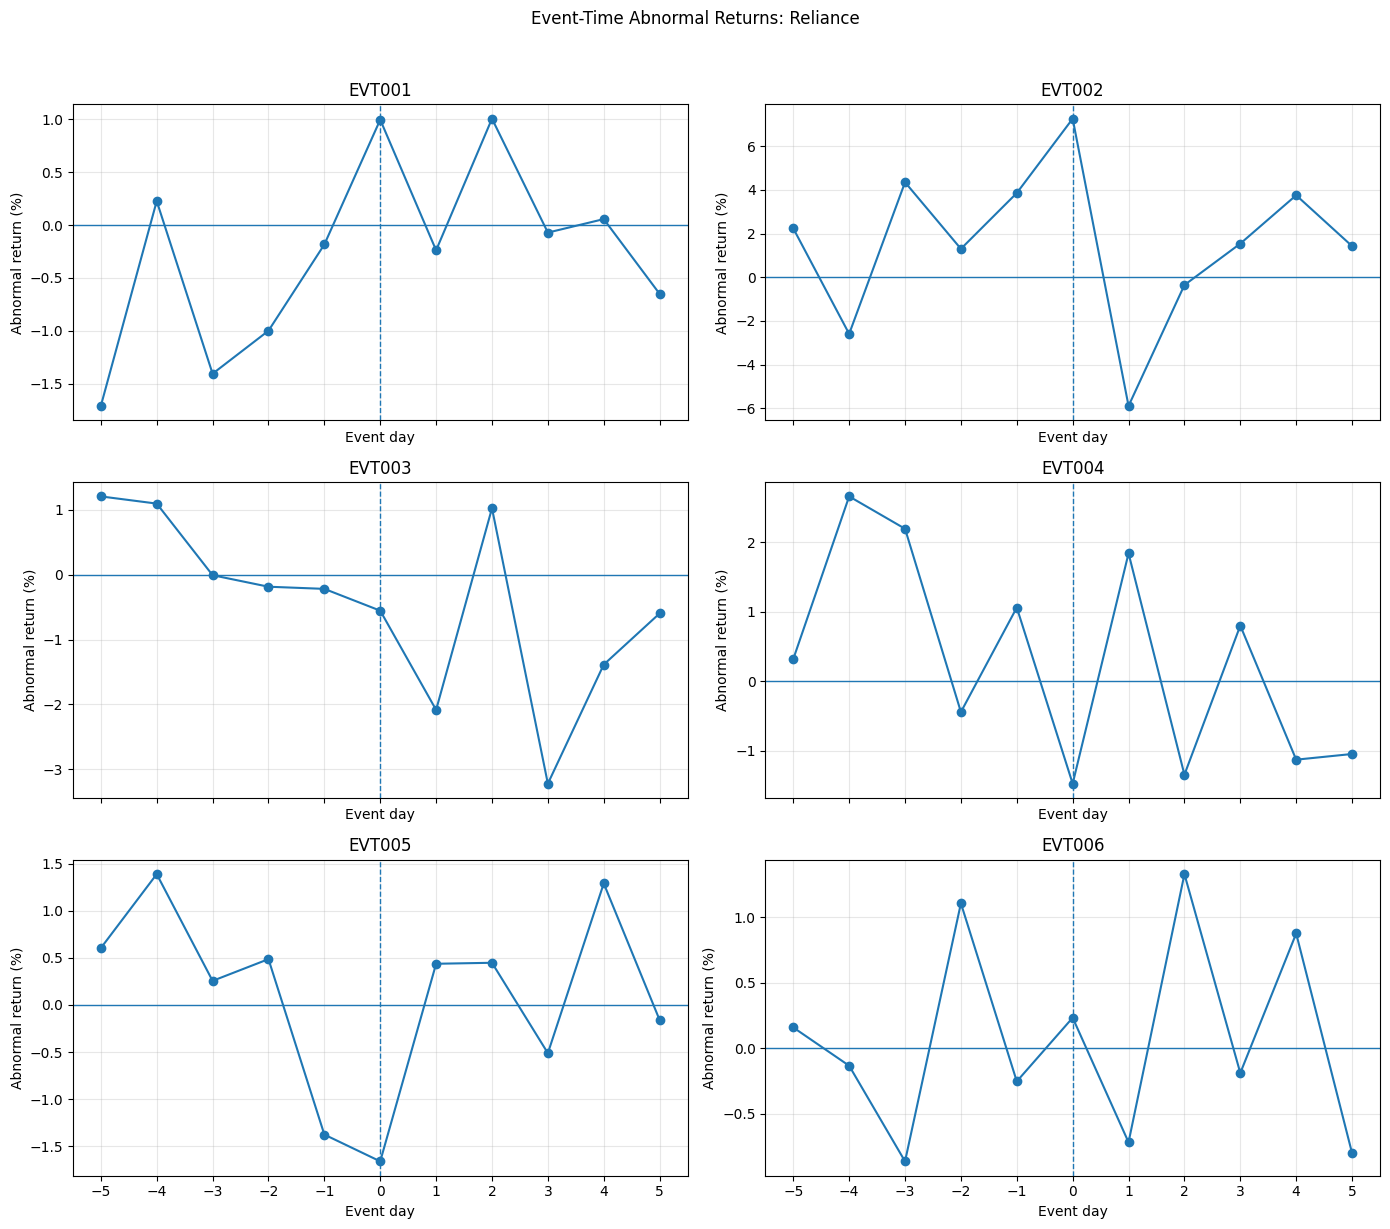

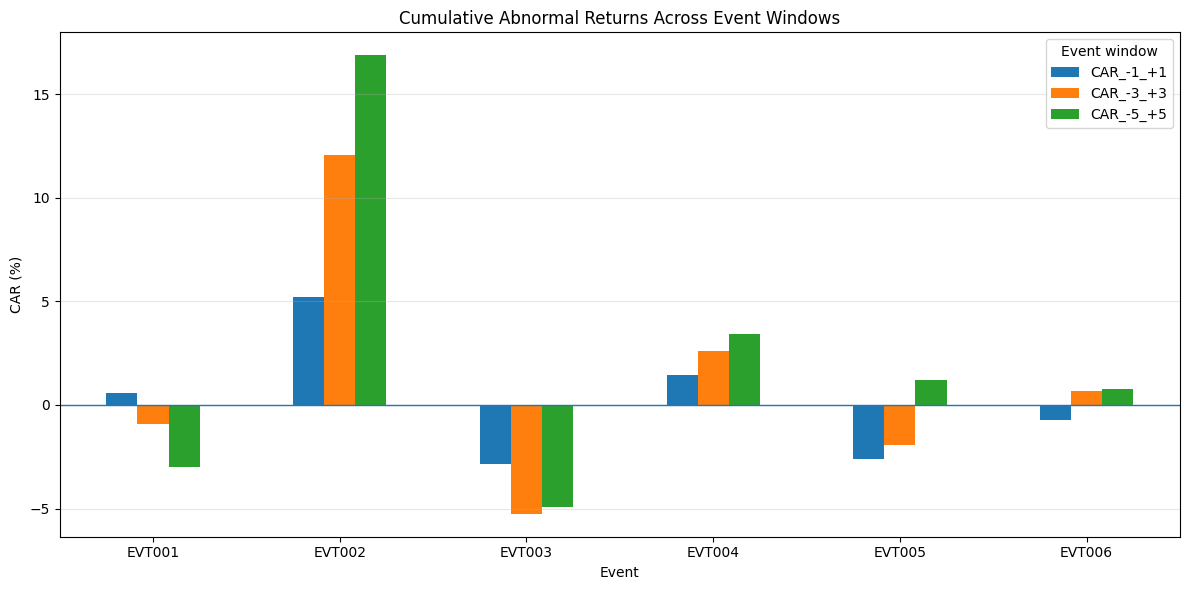

In [29]:
import matplotlib.pyplot as plt

# Plot 1: Event-time abnormal returns for each event
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)
axes = axes.flatten()

for ax, (event_id, group) in zip(
    axes, event_study.groupby("event_id", sort=True)
):
    group = group.sort_values("event_day")

    ax.plot(
        group["event_day"],
        group["ABNORMAL_RETURN"] * 100,
        marker="o"
    )
    ax.axhline(0, linewidth=1)
    ax.axvline(0, linestyle="--", linewidth=1)

    ax.set_title(event_id)
    ax.set_xlabel("Event day")
    ax.set_ylabel("Abnormal return (%)")
    ax.set_xticks(range(-5, 6))
    ax.grid(True, alpha=0.3)

plt.suptitle("Event-Time Abnormal Returns: Reliance", y=1.02)
plt.tight_layout()
plt.show()


# Plot 2: CAR comparison across windows
car_pivot = car_results.pivot(
    index="event_id",
    columns="window",
    values="CAR"
)

window_order = ["CAR_-1_+1", "CAR_-3_+3", "CAR_-5_+5"]
car_pivot = car_pivot[window_order] * 100

ax = car_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.axhline(0, linewidth=1)
ax.set_title("Cumulative Abnormal Returns Across Event Windows")
ax.set_xlabel("Event")
ax.set_ylabel("CAR (%)")
ax.legend(title="Event window")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
# Step 17.1: Summarize plot observations as text

print("EVENT-WISE ABNORMAL RETURN SUMMARY")
print("-" * 45)

for event_id, group in event_study.groupby("event_id", sort=True):
    group = group.sort_values("event_day")

    max_row = group.loc[group["ABNORMAL_RETURN"].idxmax()]
    min_row = group.loc[group["ABNORMAL_RETURN"].idxmin()]
    day_zero = group[group["event_day"] == 0].iloc[0]

    print(f"\n{event_id}")
    print(f"  Day 0 abnormal return: {day_zero['ABNORMAL_RETURN']:.2%}")
    print(
        f"  Highest AR: {max_row['ABNORMAL_RETURN']:.2%} "
        f"on Day {int(max_row['event_day']):+d}"
    )
    print(
        f"  Lowest AR:  {min_row['ABNORMAL_RETURN']:.2%} "
        f"on Day {int(min_row['event_day']):+d}"
    )

print("\nCAR SUMMARY")
print("-" * 45)

display(
    car_results.pivot(
        index="event_id",
        columns="window",
        values="CAR"
    ).style.format("{:.2%}")
)

EVENT-WISE ABNORMAL RETURN SUMMARY
---------------------------------------------

EVT001
  Day 0 abnormal return: 1.00%
  Highest AR: 1.00% on Day +2
  Lowest AR:  -1.71% on Day -5

EVT002
  Day 0 abnormal return: 7.26%
  Highest AR: 7.26% on Day +0
  Lowest AR:  -5.89% on Day +1

EVT003
  Day 0 abnormal return: -0.55%
  Highest AR: 1.21% on Day -5
  Lowest AR:  -3.23% on Day +3

EVT004
  Day 0 abnormal return: -1.48%
  Highest AR: 2.66% on Day -4
  Lowest AR:  -1.48% on Day +0

EVT005
  Day 0 abnormal return: -1.66%
  Highest AR: 1.39% on Day -4
  Lowest AR:  -1.66% on Day +0

EVT006
  Day 0 abnormal return: 0.23%
  Highest AR: 1.33% on Day +2
  Lowest AR:  -0.86% on Day -3

CAR SUMMARY
---------------------------------------------


window,CAR_-1_+1,CAR_-3_+3,CAR_-5_+5
event_id,,,
EVT001,0.57%,-0.90%,-2.98%
EVT002,5.22%,12.05%,16.87%
EVT003,-2.86%,-5.25%,-4.93%
EVT004,1.42%,2.63%,3.43%
EVT005,-2.60%,-1.92%,1.20%
EVT006,-0.73%,0.65%,0.75%


## Step 17: Visualization and Interpretation

### Key Observations

- **EVT001 — Demonetisation:** CAR changes from +0.57% in the \([-1,+1]\) window to −2.98% in the \([-5,+5]\) window. The wider window captures a more negative cumulative abnormal performance.
- **EVT002 — COVID-19 Lockdown:** CAR increases from +5.22% to +16.87% as the window widens. The event day has an abnormal return of +7.26%, the largest daily abnormal return in this sample. This period also experienced substantial market volatility and possible confounding effects.
- **EVT003 — RBI Rate Hike, May 2022:** CAR is negative across all three windows, reaching −5.25% in the \([-3,+3]\) window.
- **EVT004 — RBI Rate Hike, June 2022:** CAR is positive across all windows, increasing to +3.43% in the \([-5,+5]\) window.
- **EVT005 — RBI Rate Hike, August 2022:** CAR is negative in the shorter windows but turns positive in the \([-5,+5]\) window.
- **EVT006 — Union Budget 2025:** CAR is slightly negative in the shortest window and positive in the wider windows.

### Interpretation

The direction and magnitude of cumulative abnormal returns can vary with the selected event window. This shows why event-window selection matters. The three RBI announcements also demonstrate that events within the same broader policy cycle can have different observed reactions.

### Limitations

These are descriptive observations from six selected events involving one stock, Reliance. They do not establish causation or generalize to other companies or event categories. The daily data for announcements made during market hours may also include price movements that occurred before the announcement.

**Conclusion:** Event-time visualizations help identify patterns that summary statistics alone may obscure. These patterns must be evaluated alongside confidence intervals, multiple-testing corrections, and robustness checks.

# Step 18: Event-Window Volatility Analysis

## Objective
Measure changes in stock-return volatility around each event.

## Method
1. Calculate the standard deviation of daily stock returns during each event window.
2. Compare it with the volatility during the corresponding pre-event estimation window.
3. Calculate the volatility ratio to quantify the change.

## Formula

\[
\text{Volatility Ratio} =
\frac{\text{Event-Window Return Std. Dev.}}
{\text{Estimation-Window Return Std. Dev.}}
\]

- Ratio greater than 1: volatility was higher during the event window.
- Ratio less than 1: volatility was lower during the event window.
- Ratio approximately equal to 1: volatility was similar.

## Limitation
Volatility changes are descriptive and do not establish that the event caused the change. Results may be influenced by overlapping news, market-wide shocks, and the short length of event windows.


In [31]:
import numpy as np
import pandas as pd

volatility_rows = []

volatility_windows = {
    "Window_-1_+1": (-1, 1),
    "Window_-3_+3": (-3, 3),
    "Window_-5_+5": (-5, 5)
}

for event_id, group in event_study.groupby("event_id", sort=True):

    # Daily returns from the estimation period
    estimation_returns = estimation_samples[event_id]["RELIANCE_RETURN"]
    baseline_volatility = estimation_returns.std()

    for window_name, (lower_day, upper_day) in volatility_windows.items():

        selected = group[
            group["event_day"].between(lower_day, upper_day)
        ]

        event_volatility = selected["RELIANCE_RETURN"].std()

        volatility_ratio = (
            event_volatility / baseline_volatility
            if baseline_volatility != 0
            else np.nan
        )

        volatility_rows.append({
            "event_id": event_id,
            "window": window_name,
            "sessions": len(selected),
            "baseline_volatility": baseline_volatility,
            "event_volatility": event_volatility,
            "volatility_ratio": volatility_ratio,
            "volatility_change_pct": (volatility_ratio - 1) * 100
        })

volatility_results = pd.DataFrame(volatility_rows)

display(
    volatility_results[[
        "event_id",
        "window",
        "baseline_volatility",
        "event_volatility",
        "volatility_ratio",
        "volatility_change_pct"
    ]].style.format({
        "baseline_volatility": "{:.2%}",
        "event_volatility": "{:.2%}",
        "volatility_ratio": "{:.2f}x",
        "volatility_change_pct": "{:+.1f}%"
    })
)

,event_id,window,baseline_volatility,event_volatility,volatility_ratio,volatility_change_pct
0,EVT001,Window_-1_+1,1.14%,0.24%,0.21x,-78.8%
1,EVT001,Window_-3_+3,1.14%,0.93%,0.81x,-18.7%
2,EVT001,Window_-5_+5,1.14%,1.01%,0.88x,-11.8%
3,EVT002,Window_-1_+1,1.47%,8.10%,5.51x,+451.3%
4,EVT002,Window_-3_+3,1.47%,9.47%,6.44x,+544.2%
5,EVT002,Window_-5_+5,1.47%,8.21%,5.59x,+459.0%
6,EVT003,Window_-1_+1,1.87%,1.39%,0.74x,-25.7%
7,EVT003,Window_-3_+3,1.87%,1.80%,0.96x,-3.6%
8,EVT003,Window_-5_+5,1.87%,1.95%,1.04x,+4.0%
9,EVT004,Window_-1_+1,1.80%,2.26%,1.25x,+25.1%


## Step 18: Volatility Analysis and Interpretation

### Key Findings

- **EVT001 — Demonetisation:** Volatility was lower than the estimation-period baseline in the reported windows, with an approximately 12–19% reduction.
- **EVT002 — COVID-19 Lockdown:** Volatility increased substantially. The volatility ratio ranged from 5.51x to 6.44x the baseline, indicating exceptionally large return fluctuations during this period.
- **EVT003 — RBI Rate Hike, May 2022:** Volatility was slightly lower in the short and medium windows, but approximately 4% higher in the wider window.
- **EVT004 — RBI Rate Hike, June 2022:** Volatility was approximately 14–25% higher than baseline across the three windows.
- **EVT005 — RBI Rate Hike, August 2022:** Volatility was lower than baseline, with reductions of approximately 26–49%.
- **EVT006 — Union Budget 2025:** Short-window volatility was almost unchanged, while the wider windows showed increases of approximately 11–22%.

### Interpretation

Volatility did not move uniformly across events or event windows. The COVID-19 period showed the largest increase, whereas the reported August 2022 RBI windows showed lower volatility than their respective estimation-period baselines.

### Limitations

These estimates use standard deviations from short event windows, so they can be sensitive to individual daily returns. The COVID-19 period also contained major market-wide shocks. Lower volatility does not necessarily imply a smaller market reaction, and higher volatility does not establish causation.

**Conclusion:** Event-window volatility provides a complementary measure to CAR. CAR captures cumulative abnormal performance, whereas volatility measures the dispersion of returns. Both are needed to describe stock reactions more completely.

# Step 19: Visualizing Volatility Changes

## Objective
Compare event-window volatility against the estimation-period baseline.

## Method
Plot the volatility ratio for each event across the three event windows.

## Interpretation
A ratio above 1 indicates higher volatility than baseline; a ratio below 1 indicates lower volatility. The chart is descriptive and does not establish causation.

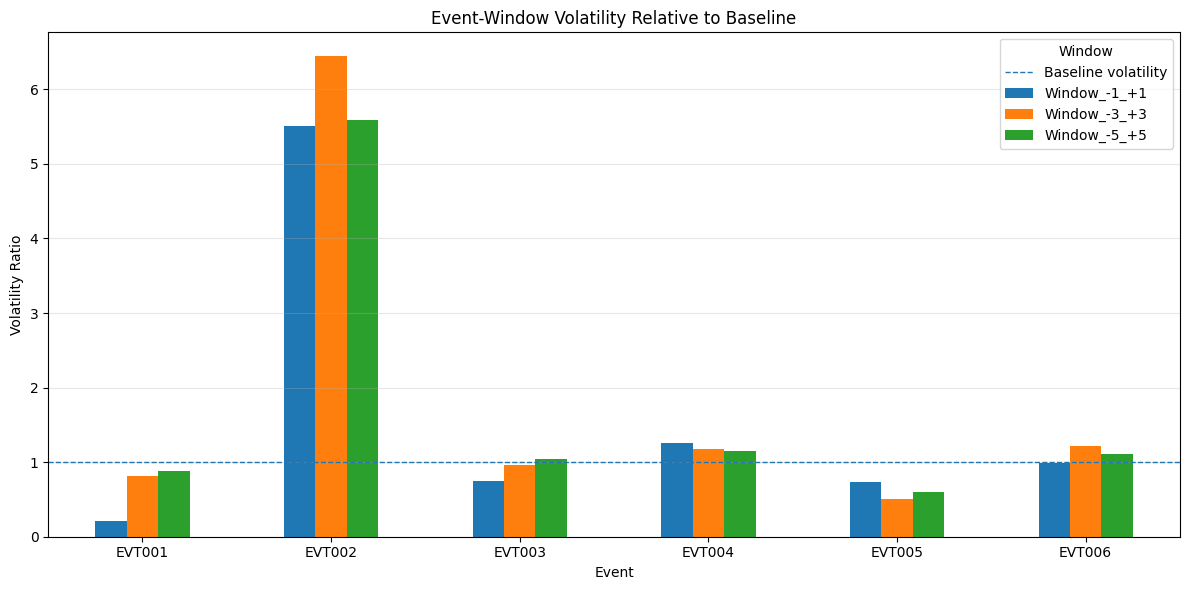

In [32]:
import matplotlib.pyplot as plt

volatility_pivot = volatility_results.pivot(
    index="event_id",
    columns="window",
    values="volatility_ratio"
)

window_order = [
    "Window_-1_+1",
    "Window_-3_+3",
    "Window_-5_+5"
]

volatility_pivot = volatility_pivot[window_order]

ax = volatility_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.axhline(
    1,
    linestyle="--",
    linewidth=1,
    label="Baseline volatility"
)

ax.set_title("Event-Window Volatility Relative to Baseline")
ax.set_xlabel("Event")
ax.set_ylabel("Volatility Ratio")
ax.legend(title="Window")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Step 20: Robustness Check — Event-Window Sensitivity

## Objective
Check whether the estimated cumulative abnormal return (CAR) remains consistent across different event-window lengths.

## Method
1. Compare CAR across the \([-1,+1]\), \([-3,+3]\), and \([-5,+5]\) windows.
2. Identify whether the CAR sign remains consistent or changes across windows.
3. Calculate the range of CAR estimates across the three windows.

## Interpretation
- Consistent signs indicate that the direction of cumulative abnormal performance is stable across the tested windows.
- A sign change indicates sensitivity to the choice of event window.
- A larger CAR range indicates greater variation in the estimated cumulative abnormal performance.

## Limitation
These windows are nested and share many of the same trading sessions. Therefore, consistency across windows is a sensitivity check, not independent confirmation of a result.


In [33]:
# Step 20.1: Compare CAR across event windows

car_wide = car_results.pivot(
    index="event_id",
    columns="window",
    values="CAR"
)

window_order = [
    "CAR_-1_+1",
    "CAR_-3_+3",
    "CAR_-5_+5"
]

car_wide = car_wide[window_order]

# Check whether the sign is consistent across all three windows
car_wide["sign_consistent"] = car_wide[window_order].apply(
    lambda row: (row > 0).all() or (row < 0).all(),
    axis=1
)

# Range of CAR estimates across windows
car_wide["CAR_range"] = (
    car_wide[window_order].max(axis=1)
    - car_wide[window_order].min(axis=1)
)

# Describe the direction across windows
def classify_direction(row):
    if (row > 0).all():
        return "Positive across all windows"
    elif (row < 0).all():
        return "Negative across all windows"
    else:
        return "Sign changes across windows"

car_wide["direction_pattern"] = car_wide[window_order].apply(
    classify_direction,
    axis=1
)

display(
    car_wide.style.format({
        "CAR_-1_+1": "{:.2%}",
        "CAR_-3_+3": "{:.2%}",
        "CAR_-5_+5": "{:.2%}",
        "CAR_range": "{:.2%}"
    })
)

window,CAR_-1_+1,CAR_-3_+3,CAR_-5_+5,sign_consistent,CAR_range,direction_pattern
event_id,,,,,,
EVT001,0.57%,-0.90%,-2.98%,False,3.55%,Sign changes across windows
EVT002,5.22%,12.05%,16.87%,True,11.65%,Positive across all windows
EVT003,-2.86%,-5.25%,-4.93%,True,2.39%,Negative across all windows
EVT004,1.42%,2.63%,3.43%,True,2.00%,Positive across all windows
EVT005,-2.60%,-1.92%,1.20%,False,3.80%,Sign changes across windows
EVT006,-0.73%,0.65%,0.75%,False,1.49%,Sign changes across windows


## Step 20: Event-Window Sensitivity — Results and Interpretation

### Key Findings

- **EVT001 — Demonetisation:** CAR changes from positive (+0.57%) in the shortest window to negative (−2.98%) in the widest window.
- **EVT002 — COVID-19 Lockdown:** CAR remains positive across all windows, increasing from +5.22% to +16.87%. The magnitude is sensitive to window length even though the direction is stable.
- **EVT003 — RBI Rate Hike, May 2022:** CAR remains negative across all windows, ranging from −2.86% to −5.25%.
- **EVT004 — RBI Rate Hike, June 2022:** CAR remains positive, increasing from +1.42% to +3.43%.
- **EVT005 — RBI Rate Hike, August 2022:** CAR changes from negative in the shorter windows to positive (+1.20%) in the widest window.
- **EVT006 — Union Budget 2025:** CAR changes from −0.73% to positive values in the wider windows.

### Conclusion

Three events show consistent CAR direction across all tested windows, while three show a sign change. The results demonstrate that the choice of event window can affect both the magnitude and direction of estimated abnormal performance.

This is a sensitivity analysis, not independent validation: the windows overlap, and consistent CAR signs do not automatically imply statistical significance or causality.

# Step 21: Robustness Check — Market Model vs. Market-Adjusted Returns

## Objective
Check whether the estimated event CARs depend on using event-specific market-model parameters.

## Methods
- **Market model:** Expected return = estimated alpha + estimated beta × benchmark return.
- **Market-adjusted method:** Expected return = benchmark return.

Calculate abnormal returns and CAR under both methods for the same events and event windows.

## Interpretation
Large differences between the two methods indicate that CAR estimates are sensitive to the expected-return model. Similar estimates suggest that the broad descriptive pattern is less dependent on this modelling choice.

## Limitation
The market-adjusted method assumes alpha is zero and beta is one. It is a useful comparison, not necessarily a more accurate model.


In [34]:
# Step 21.1: Compare market-model CAR with market-adjusted CAR

market_adjusted_study = event_study.copy()

# Market-adjusted expected return assumes alpha=0 and beta=1
market_adjusted_study["EXPECTED_RETURN_MA"] = (
    market_adjusted_study["NIFTY50_RETURN"]
)

market_adjusted_study["ABNORMAL_RETURN_MA"] = (
    market_adjusted_study["RELIANCE_RETURN"]
    - market_adjusted_study["EXPECTED_RETURN_MA"]
)

comparison_rows = []

for event_id, group in market_adjusted_study.groupby(
    "event_id", sort=True
):
    for window_name, (lower_day, upper_day) in {
        "CAR_-1_+1": (-1, 1),
        "CAR_-3_+3": (-3, 3),
        "CAR_-5_+5": (-5, 5)
    }.items():

        selected = group[
            group["event_day"].between(lower_day, upper_day)
        ]

        car_market_model = selected["ABNORMAL_RETURN"].sum()
        car_market_adjusted = selected["ABNORMAL_RETURN_MA"].sum()

        comparison_rows.append({
            "event_id": event_id,
            "window": window_name,
            "CAR_market_model": car_market_model,
            "CAR_market_adjusted": car_market_adjusted,
            "difference": car_market_adjusted - car_market_model
        })

model_comparison = pd.DataFrame(comparison_rows)

display(
    model_comparison.style.format({
        "CAR_market_model": "{:.2%}",
        "CAR_market_adjusted": "{:.2%}",
        "difference": "{:+.2%}"
    })
)

,event_id,window,CAR_market_model,CAR_market_adjusted,difference
0,EVT001,CAR_-1_+1,0.57%,0.57%,-0.00%
1,EVT001,CAR_-3_+3,-0.90%,0.65%,+1.55%
2,EVT001,CAR_-5_+5,-2.98%,-0.70%,+2.28%
3,EVT002,CAR_-1_+1,5.22%,6.93%,+1.71%
4,EVT002,CAR_-3_+3,12.05%,12.65%,+0.60%
5,EVT002,CAR_-5_+5,16.87%,16.74%,-0.13%
6,EVT003,CAR_-1_+1,-2.86%,-2.97%,-0.11%
7,EVT003,CAR_-3_+3,-5.25%,-5.29%,-0.04%
8,EVT003,CAR_-5_+5,-4.93%,-4.65%,+0.28%
9,EVT004,CAR_-1_+1,1.42%,1.72%,+0.30%


## Step 21: Expected-Return Model Robustness — Results and Interpretation

### Key Findings

- **EVT001 — Demonetisation:** The market-model CAR is negative in the wider windows, while the market-adjusted CAR is slightly positive in the \([-3,+3]\) window. The estimated market-model parameters affect the result.
- **EVT002 — COVID-19 Lockdown:** Both methods show positive CAR across all windows. Their estimates are relatively similar in the wider windows.
- **EVT003 — RBI Rate Hike, May 2022:** Both methods produce similar negative CAR estimates across all three windows.
- **EVT004 — RBI Rate Hike, June 2022:** Both methods produce positive CAR estimates, with modest differences in magnitude.
- **EVT005 — RBI Rate Hike, August 2022:** The widest-window CAR is positive under both methods, while the shorter-window estimates are negative.
- **EVT006 — Union Budget 2025:** The market-model CAR is slightly positive in the widest window, whereas the market-adjusted CAR is negative.

### Conclusion

The broad descriptive patterns for COVID-19 and the May and June 2022 RBI announcements are relatively stable across the two expected-return methods. Demonetisation and the Union Budget show greater sensitivity in some windows.

The market-adjusted method assumes a benchmark beta of one and alpha of zero, so neither method should automatically be treated as correct. These comparisons assess model sensitivity; they do not establish causality or statistical significance under the alternative method.

# Step 22: Event-Date Alignment Validation

## Objective
Verify that each event is aligned to the intended trading session in the return dataset.

## Checks
1. Confirm that every effective event date exists in the trading-date index.
2. Confirm that Day 0 in the event-study data matches the effective event date.
3. Identify missing or mismatched dates before further analysis.

## Limitation
A matching date confirms data alignment, not necessarily that the daily return isolates the market's reaction after the announcement. Intraday announcements require intraday prices for cleaner reaction measurement.

In [35]:
# Step 22.1: Validate event dates and Day 0 alignment

alignment_rows = []

for _, event in events.iterrows():
    event_id = event["event_id"]
    effective_date = pd.Timestamp(
        event["effective_event_date"]
    ).normalize()

    date_exists_in_returns = effective_date in returns.index

    event_rows = event_study[
        event_study["event_id"] == event_id
    ]

    day_zero_rows = event_rows[event_rows["event_day"] == 0]

    day_zero_date = (
        pd.Timestamp(day_zero_rows["trading_date"].iloc[0]).normalize()
        if not day_zero_rows.empty
        else pd.NaT
    )

    alignment_rows.append({
        "event_id": event_id,
        "effective_event_date": effective_date,
        "date_exists_in_returns": date_exists_in_returns,
        "day_zero_date": day_zero_date,
        "day_zero_matches": (
            not pd.isna(day_zero_date)
            and day_zero_date == effective_date
        )
    })

alignment_check = pd.DataFrame(alignment_rows)

display(alignment_check)

print(
    "All event dates exist in returns:",
    alignment_check["date_exists_in_returns"].all()
)
print(
    "All Day 0 dates match effective dates:",
    alignment_check["day_zero_matches"].all()
)

,event_id,effective_event_date,date_exists_in_returns,day_zero_date,day_zero_matches
0,EVT001,2016-11-09,True,2016-11-09,True
1,EVT002,2020-03-25,True,2020-03-25,True
2,EVT003,2022-05-04,True,2022-05-04,True
3,EVT004,2022-06-08,True,2022-06-08,True
4,EVT005,2022-08-05,True,2022-08-05,True
5,EVT006,2025-02-01,True,2025-02-01,True


All event dates exist in returns: True
All Day 0 dates match effective dates: True


## Step 22: Event-Date Alignment — Results and Interpretation

### Results
- All six effective event dates exist in the trading-return dataset.
- Day 0 matches the effective event date for all six events.
- No missing or mismatched event dates were detected.

### Limitation
This check validates date alignment only. For announcements released during market hours, close-to-close daily returns may include price movements that occurred before the announcement. The Union Budget event also took place during a special Saturday trading session.

**Conclusion:** Event-date alignment is validated for the current dataset. The timing limitation should remain documented when interpreting event reactions.

# Step 23: Systematic Event Sample Expansion

## Objective
Expand the initial six-event sample into a broader, systematically selected dataset suitable for comparative analysis.

## Event Categories
1. Corporate earnings announcements
2. Monetary policy decisions
3. Government budgets and major policy announcements
4. Macroeconomic releases
5. Major geopolitical or commodity-related shocks

## Event Inclusion Rules
- The event must have a verifiable source and date.
- The event date must be aligned to the appropriate trading session.
- Event selection must not depend on whether the stock price increased or decreased.
- Events belonging to the same broader episode must share an episode identifier.
- Potentially overlapping events and confounding announcements must be documented.
- Events with uncertain timing must be flagged rather than assigned an invented timestamp.

## Objective for the Expanded Dataset
Create a reproducible event master that supports comparisons across event categories, companies, and event windows.

## Limitation
The expanded sample must be audited for completeness and selection bias. A larger event count alone does not guarantee reliable statistical inference, especially when events belong to the same underlying episode.

In [36]:
# Step 23.1: Create a structured template for additional events

additional_event_columns = [
    "event_id",
    "event_date",
    "event_time",
    "headline",
    "category",
    "source_name",
    "source_url",
    "affected_stocks",
    "episode_id",
    "timing_confidence",
    "overlap_flag",
    "inclusion_reason",
    "verification_status",
    "notes"
]

additional_events = pd.DataFrame(
    columns=additional_event_columns
)

# Define the event categories to be considered
allowed_categories = [
    "Corporate Earnings",
    "Monetary Policy",
    "Government Policy",
    "Macroeconomic Release",
    "Geopolitical Event",
    "Commodity Shock"
]

print("Event categories:")
for category in allowed_categories:
    print("-", category)

print("\nExisting seed events:", len(events))
print("New-event template rows:", len(additional_events))
print("Template columns:", len(additional_event_columns))

Event categories:
- Corporate Earnings
- Monetary Policy
- Government Policy
- Macroeconomic Release
- Geopolitical Event
- Commodity Shock

Existing seed events: 6
New-event template rows: 0
Template columns: 14


## Step 23: Adding Source-Verified Monetary Policy Events

The following RBI policy announcements are added to expand the initial event sample. Dates are verified against official RBI press releases. Exact announcement timestamps and trading-session alignment remain pending verification.

Events are included based on their category and source availability, not on the direction of subsequent stock returns.

Overlap and episode checks must be rerun after the new events are added.

In [37]:
# Step 23.2: Add three source-verified RBI policy events

new_rbi_events = pd.DataFrame([
    {
        "event_id": "EVT007",
        "event_date": "2023-02-08",
        "event_time": None,
        "headline": "RBI raises policy repo rate by 25 basis points",
        "category": "Monetary Policy",
        "source_name": "Reserve Bank of India",
        "source_url": "https://systemhealth.rbi.org.in/Scripts/BS_PressReleaseDisplay.aspx_prid%3D55178.html",
        "affected_stocks": "RELIANCE.NS",
        "episode_id": "RBI_POLICY_2023",
        "timing_confidence": "Date verified; exact time pending",
        "overlap_flag": None,
        "inclusion_reason": "RBI monetary-policy decision; selected by category, not stock reaction",
        "verification_status": "Primary-source date verified; alignment pending",
        "notes": "Repo rate increased to 6.50%; verify event-session alignment"
    },
    {
        "event_id": "EVT008",
        "event_date": "2023-10-06",
        "event_time": None,
        "headline": "RBI keeps policy repo rate unchanged at 6.50%",
        "category": "Monetary Policy",
        "source_name": "Reserve Bank of India",
        "source_url": "https://systemhealth.rbi.org.in/Scripts/BS_PressReleaseDisplay.aspx_prid%3D56502.html",
        "affected_stocks": "RELIANCE.NS",
        "episode_id": "RBI_POLICY_2023",
        "timing_confidence": "Date verified; exact time pending",
        "overlap_flag": None,
        "inclusion_reason": "RBI monetary-policy decision; selected by category, not stock reaction",
        "verification_status": "Primary-source date verified; alignment pending",
        "notes": "Repo rate unchanged; verify event-session alignment"
    },
    {
        "event_id": "EVT009",
        "event_date": "2024-10-09",
        "event_time": None,
        "headline": "RBI keeps repo rate unchanged and changes policy stance to neutral",
        "category": "Monetary Policy",
        "source_name": "Reserve Bank of India",
        "source_url": "https://systemhealth.rbi.org.in/Scripts/BS_PressReleaseDisplay.aspx_prid%3D58850.html",
        "affected_stocks": "RELIANCE.NS",
        "episode_id": "RBI_POLICY_2024",
        "timing_confidence": "Date verified; exact time pending",
        "overlap_flag": None,
        "inclusion_reason": "RBI monetary-policy decision; selected by category, not stock reaction",
        "verification_status": "Primary-source date verified; alignment pending",
        "notes": "Policy stance changed to neutral; verify event-session alignment"
    }
])

# Standardize dates
new_rbi_events["event_date"] = pd.to_datetime(
    new_rbi_events["event_date"]
)

# Add only event IDs not already present
existing_ids = set(additional_events["event_id"].dropna())
new_rbi_events = new_rbi_events[
    ~new_rbi_events["event_id"].isin(existing_ids)
]

additional_events = pd.concat(
    [additional_events, new_rbi_events],
    ignore_index=True
)

print("New RBI events added:", len(new_rbi_events))
print("Total additional events:", len(additional_events))

display(
    additional_events[[
        "event_id",
        "event_date",
        "headline",
        "category",
        "verification_status",
        "timing_confidence"
    ]]
)

New RBI events added: 3
Total additional events: 3


/tmp/ipykernel_49/2982991920.py:65: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  additional_events = pd.concat(


,event_id,event_date,headline,category,verification_status,timing_confidence
0,EVT007,2023-02-08,RBI raises policy repo rate by 25 basis points,Monetary Policy,Primary-source date verified; alignment pending,Date verified; exact time pending
1,EVT008,2023-10-06,RBI keeps policy repo rate unchanged at 6.50%,Monetary Policy,Primary-source date verified; alignment pending,Date verified; exact time pending
2,EVT009,2024-10-09,RBI keeps repo rate unchanged and changes poli...,Monetary Policy,Primary-source date verified; alignment pending,Date verified; exact time pending


### Step 23.5: Verify Trading-Session Alignment

Before using the three additional RBI events in the event study, check whether each official announcement date exists in the stock-return dataset.

A date appearing in the trading calendar does not, by itself, prove the exact announcement time. We will keep timing uncertainty documented rather than inventing timestamps. Events will be aligned to the same session only after the timing review.

In [38]:
# Step 23.5: Check RBI event dates against available trading sessions

rbi_dates = additional_events[
    additional_events["event_id"].isin(["EVT007", "EVT008", "EVT009"])
].copy()

available_dates = pd.DatetimeIndex(returns.index).normalize()

alignment_check = []

for _, event in rbi_dates.iterrows():
    event_date = pd.Timestamp(event["event_date"]).normalize()
    is_trading_session = event_date in available_dates

    alignment_check.append({
        "event_id": event["event_id"],
        "official_event_date": event_date.date(),
        "date_in_returns_data": is_trading_session,
        "provisional_effective_date": (
            event_date.date() if is_trading_session else None
        ),
        "timing_status": "Pending exact-time verification"
    })

alignment_check = pd.DataFrame(alignment_check)
display(alignment_check)

,event_id,official_event_date,date_in_returns_data,provisional_effective_date,timing_status
0,EVT007,2023-02-08,True,2023-02-08,Pending exact-time verification
1,EVT008,2023-10-06,True,2023-10-06,Pending exact-time verification
2,EVT009,2024-10-09,True,2024-10-09,Pending exact-time verification


### Step 23.6: Record Trading-Calendar Validation

All three additional RBI event dates are present in the available trading-return dataset. This confirms that the dates can be mapped to trading sessions, but does not independently verify the precise announcement time.

We will record the calendar check and retain the timing caveat before combining these events with the original event master.

In [39]:
# Step 23.6: Update verification status without assuming exact announcement times

for _, row in alignment_check.iterrows():
    mask = additional_events["event_id"] == row["event_id"]

    if row["date_in_returns_data"]:
        additional_events.loc[mask, "verification_status"] = (
            "Primary-source date verified; trading session confirmed; "
            "exact timing pending"
        )
        additional_events.loc[mask, "timing_confidence"] = (
            "Date/session verified; exact announcement time pending"
        )

display(
    additional_events[
        additional_events["event_id"].isin(["EVT007", "EVT008", "EVT009"])
    ][[
        "event_id",
        "event_date",
        "verification_status",
        "timing_confidence"

    ]]
)

,event_id,event_date,verification_status,timing_confidence
0,EVT007,2023-02-08,Primary-source date verified; trading session ...,Date/session verified; exact announcement time...
1,EVT008,2023-10-06,Primary-source date verified; trading session ...,Date/session verified; exact announcement time...
2,EVT009,2024-10-09,Primary-source date verified; trading session ...,Date/session verified; exact announcement time...


### Step 23.7: Combine the Original and Additional Event Records

The original six seed events and three additional RBI events will be combined into a separate master dataset. A common schema will be used, and the provisional effective event dates will remain separate from the original announcement dates.

This creates a consistent dataset for subsequent event-window calculations while preserving the original records.

In [40]:
# Step 23.7: Build an expanded event master without changing `events`

# Standardize the original six-event dataset
original_master = events.copy()

if "event_date" in original_master.columns:
    original_master["event_date"] = pd.to_datetime(
        original_master["event_date"]
    )

if "affected_stocks" not in original_master.columns:
    original_master["affected_stocks"] = "RELIANCE.NS"

if "inclusion_reason" not in original_master.columns:
    original_master["inclusion_reason"] = (
        "Original seed event; retained for initial methodology demonstration"
    )

if "verification_status" not in original_master.columns:
    original_master["verification_status"] = (
        "Previously recorded source verification; review before final study"
    )

if "effective_event_date" not in original_master.columns:
    original_master["effective_event_date"] = pd.NaT

# Add the provisional effective dates for the original six events
original_effective_dates = {
    "EVT001": "2016-11-09",
    "EVT002": "2020-03-25",
    "EVT003": "2022-05-04",
    "EVT004": "2022-06-08",
    "EVT005": "2022-08-05",
    "EVT006": "2025-02-01",
}

original_master["effective_event_date"] = (
    original_master["event_id"]
    .map(original_effective_dates)
    .pipe(pd.to_datetime)
)

# Prepare the additional records
extra_master = additional_events.copy()

extra_master["effective_event_date"] = extra_master["event_id"].map(
    {
        "EVT007": "2023-02-08",
        "EVT008": "2023-10-06",
        "EVT009": "2024-10-09",
    }
)
extra_master["effective_event_date"] = pd.to_datetime(
    extra_master["effective_event_date"]
)

# Keep only columns common to both datasets
master_columns = [
    "event_id",
    "event_date",
    "effective_event_date",
    "event_time",
    "headline",
    "category",
    "source_name",
    "source_url",
    "affected_stocks",
    "episode_id",
    "timing_confidence",
    "overlap_flag",
    "inclusion_reason",
    "verification_status",
    "notes",
]

for col in master_columns:
    if col not in original_master.columns:
        original_master[col] = None
    if col not in extra_master.columns:
        extra_master[col] = None

expanded_events = pd.concat(
    [
        original_master[master_columns],
        extra_master[master_columns],
    ],
    ignore_index=True
)

expanded_events = expanded_events.sort_values(
    "effective_event_date"
).reset_index(drop=True)

print("Original seed events:", len(events))
print("Additional events:", len(additional_events))
print("Expanded event master:", len(expanded_events))
print("Unique event IDs:", expanded_events["event_id"].nunique())

display(
    expanded_events[
        [
            "event_id",
            "event_date",
            "effective_event_date",
            "category",
            "headline",
            "timing_confidence",
        ]
    ]
)

Original seed events: 6
Additional events: 3
Expanded event master: 9
Unique event IDs: 9


,event_id,event_date,effective_event_date,category,headline,timing_confidence
0,EVT001,2016-11-08,2016-11-09,Government Policy,India demonetisation announcement,high_date_time_not_in_master
1,EVT002,2020-03-24,2020-03-25,Public Health / Government Policy,Nationwide COVID-19 lockdown announced,high_date_time_not_in_master
2,EVT003,2022-05-04,2022-05-04,Monetary Policy,RBI raises repo rate by 40 basis points,date_verified_time_unverified
3,EVT004,2022-06-08,2022-06-08,Monetary Policy,RBI raises repo rate by 50 basis points,date_verified_time_unverified
4,EVT005,2022-08-05,2022-08-05,Monetary Policy,RBI raises repo rate by 50 basis points,date_verified_time_unverified
5,EVT007,2023-02-08,2023-02-08,Monetary Policy,RBI raises policy repo rate by 25 basis points,Date/session verified; exact announcement time...
6,EVT008,2023-10-06,2023-10-06,Monetary Policy,RBI keeps policy repo rate unchanged at 6.50%,Date/session verified; exact announcement time...
7,EVT009,2024-10-09,2024-10-09,Monetary Policy,RBI keeps repo rate unchanged and changes poli...,Date/session verified; exact announcement time...
8,EVT006,2025-02-01,2025-02-01,Government Policy / Budget,Union Budget 2025-26 presented,date_verified_session_check_required


### Step 23.8: Event Master Quality Checks

Validate that every event has a unique ID, a usable effective event date, and a matching date in the return dataset. Identify missing source or timing metadata rather than silently filling it with assumptions.

Special trading sessions and uncertain announcement times must remain documented. Passing these checks confirms data consistency, not the validity of causal claims.

In [41]:
# Step 23.8: Audit all nine events

audit = expanded_events.copy()

audit["effective_event_date"] = pd.to_datetime(
    audit["effective_event_date"], errors="coerce"
).dt.normalize()

available_dates = pd.DatetimeIndex(returns.index).normalize()

audit["date_in_returns_data"] = audit["effective_event_date"].isin(
    available_dates
)

audit["missing_effective_date"] = audit["effective_event_date"].isna()
audit["missing_source_url"] = (
    audit["source_url"].isna()
    | audit["source_url"].astype(str).str.strip().eq("")
)
audit["missing_episode_id"] = (
    audit["episode_id"].isna()
    | audit["episode_id"].astype(str).str.strip().eq("")
)

print("Rows:", len(audit))
print("Unique event IDs:", audit["event_id"].nunique())
print("Duplicate event IDs:", audit["event_id"].duplicated().sum())
print("Effective dates found in returns:", audit["date_in_returns_data"].sum(), "/", len(audit))

display(
    audit[
        [
            "event_id",
            "effective_event_date",
            "date_in_returns_data",
            "missing_effective_date",
            "missing_source_url",
            "missing_episode_id",
            "timing_confidence",
        ]
    ]
)

Rows: 9
Unique event IDs: 9
Duplicate event IDs: 0
Effective dates found in returns: 9 / 9


,event_id,effective_event_date,date_in_returns_data,missing_effective_date,missing_source_url,missing_episode_id,timing_confidence
0,EVT001,2016-11-09,True,False,False,False,high_date_time_not_in_master
1,EVT002,2020-03-25,True,False,False,False,high_date_time_not_in_master
2,EVT003,2022-05-04,True,False,False,False,date_verified_time_unverified
3,EVT004,2022-06-08,True,False,False,False,date_verified_time_unverified
4,EVT005,2022-08-05,True,False,False,False,date_verified_time_unverified
5,EVT007,2023-02-08,True,False,False,False,Date/session verified; exact announcement time...
6,EVT008,2023-10-06,True,False,False,False,Date/session verified; exact announcement time...
7,EVT009,2024-10-09,True,False,False,False,Date/session verified; exact announcement time...
8,EVT006,2025-02-01,True,False,False,False,date_verified_session_check_required


### Step 23.9: Rebuild Estimation Samples

For each event, use 100 trading-session observations ending 21 sessions before the effective event date. This leaves a 20-session buffer between the estimation period and the event window.

The estimation sample is used to fit a separate market model for each event. This step checks data availability only; it does not yet calculate new abnormal returns or significance tests.

In [42]:
# Step 23.9: Build 100-session estimation samples for all 9 events

estimation_length = 100
buffer_length = 20

trading_dates = pd.DatetimeIndex(returns.index).normalize().unique().sort_values()

expanded_estimation_samples = {}
estimation_window_rows = []

for _, event in expanded_events.iterrows():
    event_id = event["event_id"]
    event_date = pd.Timestamp(event["effective_event_date"]).normalize()

    event_positions = [
        i for i, date in enumerate(trading_dates)
        if date == event_date
    ]

    if not event_positions:
        estimation_window_rows.append({
            "event_id": event_id,
            "event_date": event_date,
            "estimation_observations": 0,
            "estimation_start": None,
            "estimation_end": None,
            "status": "Event date not found"
        })
        continue

    event_pos = event_positions[0]
    estimation_end_pos = event_pos - buffer_length
    estimation_start_pos = estimation_end_pos - estimation_length + 1

    if estimation_start_pos < 0:
        estimation_window_rows.append({
            "event_id": event_id,
            "event_date": event_date,
            "estimation_observations": 0,
            "estimation_start": None,
            "estimation_end": None,
            "status": "Insufficient prior history"
        })
        continue

    sample_dates = trading_dates[
        estimation_start_pos:estimation_end_pos + 1
    ]

    sample = returns.loc[
        sample_dates, ["RELIANCE_RETURN", "NIFTY50_RETURN"]
    ].dropna()

    if len(sample) == estimation_length:
        expanded_estimation_samples[event_id] = sample
        status = "OK"
    else:
        status = "Incomplete estimation sample"

    estimation_window_rows.append({
        "event_id": event_id,
        "event_date": event_date,
        "estimation_observations": len(sample),
        "estimation_start": sample.index.min() if len(sample) else None,
        "estimation_end": sample.index.max() if len(sample) else None,
        "status": status
    })

expanded_estimation_summary = pd.DataFrame(estimation_window_rows)

print("Events in master:", len(expanded_events))
print("Valid estimation samples:", len(expanded_estimation_samples))

display(expanded_estimation_summary)

Events in master: 9
Valid estimation samples: 9


,event_id,event_date,estimation_observations,estimation_start,estimation_end,status
0,EVT001,2016-11-09,100,2016-05-16,2016-10-07,OK
1,EVT002,2020-03-25,100,2019-09-30,2020-02-25,OK
2,EVT003,2022-05-04,100,2021-11-09,2022-04-01,OK
3,EVT004,2022-06-08,100,2021-12-15,2022-05-11,OK
4,EVT005,2022-08-05,100,2022-02-14,2022-07-08,OK
5,EVT007,2023-02-08,100,2022-08-18,2023-01-10,OK
6,EVT008,2023-10-06,100,2023-04-17,2023-09-06,OK
7,EVT009,2024-10-09,100,2024-04-16,2024-09-10,OK
8,EVT006,2025-02-01,100,2024-08-13,2025-01-06,OK


### Step 23.10: Estimate Event-Specific Market Models

Fit an OLS market model using each event's estimation period. The model estimates alpha and beta from pre-event returns, then provides the expected-return baseline for calculating abnormal returns.

These model parameters describe the estimation period; they do not establish whether the event itself had a statistically significant effect.

In [43]:
# Step 23.10: Fit one market model per event

import statsmodels.api as sm
import numpy as np
import pandas as pd

expanded_event_models = {}
expanded_model_rows = []

for event_id, sample in expanded_estimation_samples.items():
    X = sm.add_constant(sample["NIFTY50_RETURN"])
    y = sample["RELIANCE_RETURN"]

    model = sm.OLS(y, X).fit()
    expanded_event_models[event_id] = model

    expanded_model_rows.append({
        "event_id": event_id,
        "observations": int(model.nobs),
        "alpha_daily_pct": model.params["const"] * 100,
        "beta": model.params["NIFTY50_RETURN"],
        "r_squared": model.rsquared,
        "alpha_p_value": model.pvalues["const"],
        "beta_p_value": model.pvalues["NIFTY50_RETURN"]
    })

expanded_model_summary = pd.DataFrame(expanded_model_rows)

display(
    expanded_model_summary.round({
        "alpha_daily_pct": 4,
        "beta": 4,
        "r_squared": 4,
        "alpha_p_value": 4,
        "beta_p_value": 4
    })
)

,event_id,observations,alpha_daily_pct,beta,r_squared,alpha_p_value,beta_p_value
0,EVT001,100,0.0335,0.7040,0.2165,0.7444,0.0
1,EVT002,100,0.0568,1.1179,0.3295,0.6396,0.0
2,EVT003,100,0.0937,1.1600,0.6106,0.4270,0.0
3,EVT004,100,0.1096,1.0620,0.5612,0.3641,0.0
4,EVT005,100,0.0920,1.0623,0.4524,0.5602,0.0
5,EVT007,100,-0.0318,1.0584,0.5180,0.7185,0.0
6,EVT008,100,-0.0019,1.2588,0.3673,0.9825,0.0
7,EVT009,100,-0.1300,1.1630,0.6192,0.1677,0.0
8,EVT006,100,-0.1375,1.2131,0.6259,0.0729,0.0


### Step 23.11: Calculate Abnormal Returns for All Events

For each event, calculate expected Reliance returns using its own estimated market model. Abnormal return is actual return minus expected return. Then aggregate abnormal returns across event days −5 to +5 and calculate CAR for the −1 to +1, −3 to +3, and −5 to +5 windows.

These are descriptive estimates; statistical significance and confounding events must be assessed separately.

In [44]:
# Step 23.11: Calculate event-time abnormal returns and CARs

event_window_days = range(-5, 6)
expanded_event_study_rows = []

for _, event in expanded_events.iterrows():
    event_id = event["event_id"]
    event_date = pd.Timestamp(event["effective_event_date"]).normalize()

    if event_id not in expanded_event_models:
        continue

    event_position = trading_dates.get_loc(event_date)
    model = expanded_event_models[event_id]

    for event_day in event_window_days:
        position = event_position + event_day

        if position < 0 or position >= len(trading_dates):
            continue

        trading_date = trading_dates[position]

        if trading_date not in returns.index:
            continue

        actual_stock_return = returns.loc[trading_date, "RELIANCE_RETURN"]
        market_return = returns.loc[trading_date, "NIFTY50_RETURN"]

        expected_stock_return = (
            model.params["const"]
            + model.params["NIFTY50_RETURN"] * market_return
        )

        abnormal_return = actual_stock_return - expected_stock_return

        expanded_event_study_rows.append({
            "event_id": event_id,
            "event_date": event_date,
            "trading_date": trading_date,
            "event_day": event_day,
            "actual_return": actual_stock_return,
            "market_return": market_return,
            "expected_return": expected_stock_return,
            "abnormal_return": abnormal_return
        })

expanded_event_study = pd.DataFrame(expanded_event_study_rows)

window_specs = {
    "CAR_-1_+1": (-1, 1),
    "CAR_-3_+3": (-3, 3),
    "CAR_-5_+5": (-5, 5)
}

expanded_car_rows = []

for event_id, group in expanded_event_study.groupby("event_id"):
    for window_name, (lower_day, upper_day) in window_specs.items():
        selected = group[
            group["event_day"].between(lower_day, upper_day)
        ]

        expanded_car_rows.append({
            "event_id": event_id,
            "window": window_name,
            "sessions_included": len(selected),
            "CAR_pct": selected["abnormal_return"].sum() * 100
        })

expanded_car_results = pd.DataFrame(expanded_car_rows)

print("Events with event-study observations:",
      expanded_event_study["event_id"].nunique())
print("Event-time observations:", len(expanded_event_study))

display(
    expanded_car_results.pivot(
        index="event_id",
        columns="window",
        values="CAR_pct"
    ).round(2)
)

Events with event-study observations: 9
Event-time observations: 99


window,CAR_-1_+1,CAR_-3_+3,CAR_-5_+5
event_id,,,
EVT001,0.57,-0.90,-2.98
EVT002,5.22,12.05,16.87
EVT003,-2.86,-5.25,-4.93
EVT004,1.42,2.63,3.43
EVT005,-2.60,-1.92,1.20
EVT006,-0.73,0.65,0.75
EVT007,1.26,-0.88,1.58
EVT008,-1.18,-1.08,-1.02
EVT009,-0.51,-0.97,-3.27


### Step 23.12: Preliminary Significance Tests

Calculate preliminary confidence intervals and p-values for each event-window CAR using the event-specific market-model residual standard deviation. Apply the Holm correction across all 27 tests (9 events × 3 windows) to reduce false positives from multiple comparisons.

This is a preliminary diagnostic. The simplified standard error does not fully account for parameter uncertainty, serial dependence, or event-induced volatility, so results must not be presented as definitive inference.

In [45]:
# Step 23.12: Preliminary CAR significance and Holm correction

from scipy import stats
from statsmodels.stats.multitest import multipletests

significance_rows = []

for _, row in expanded_car_results.iterrows():
    event_id = row["event_id"]
    window_name = row["window"]
    car = row["CAR_pct"] / 100

    model = expanded_event_models[event_id]
    residual_std = np.sqrt(model.mse_resid)
    sessions = int(row["sessions_included"])

    standard_error = residual_std * np.sqrt(sessions)
    t_stat = car / standard_error
    df = int(model.df_resid)

    p_value = 2 * stats.t.sf(abs(t_stat), df=df)
    critical_value = stats.t.ppf(0.975, df=df)

    significance_rows.append({
        "event_id": event_id,
        "window": window_name,
        "CAR_pct": row["CAR_pct"],
        "standard_error_pct": standard_error * 100,
        "t_stat": t_stat,
        "p_value": p_value,
        "ci_lower_pct": (car - critical_value * standard_error) * 100,
        "ci_upper_pct": (car + critical_value * standard_error) * 100
    })

expanded_car_significance = pd.DataFrame(significance_rows)

expanded_car_significance["holm_p_value"] = multipletests(
    expanded_car_significance["p_value"],
    method="holm"
)[1]

expanded_car_significance["significant_after_holm_5pct"] = (
    expanded_car_significance["holm_p_value"] < 0.05
)

display(
    expanded_car_significance[
        [
            "event_id", "window", "CAR_pct",
            "ci_lower_pct", "ci_upper_pct",
            "p_value", "holm_p_value",
            "significant_after_holm_5pct"
        ]
    ].round(4)
)

,event_id,window,CAR_pct,ci_lower_pct,ci_upper_pct,p_value,holm_p_value,significant_after_holm_5pct
0,EVT001,CAR_-1_+1,0.5723,-2.9140,4.0586,0.7453,1.0000,False
1,EVT001,CAR_-3_+3,-0.8995,-6.2249,4.4260,0.7382,1.0000,False
2,EVT001,CAR_-5_+5,-2.9785,-9.6543,3.6973,0.3781,1.0000,False
3,EVT002,CAR_-1_+1,5.2204,1.0635,9.3772,0.0144,0.3593,False
4,EVT002,CAR_-3_+3,12.0495,5.6997,18.3992,0.0003,0.0074,True
5,EVT002,CAR_-5_+5,16.8719,8.9121,24.8317,0.0001,0.0016,True
6,EVT003,CAR_-1_+1,-2.8601,-6.8983,1.1782,0.1630,1.0000,False
7,EVT003,CAR_-3_+3,-5.2512,-11.4197,0.9174,0.0943,1.0000,False
8,EVT003,CAR_-5_+5,-4.9268,-12.6595,2.8058,0.2091,1.0000,False
9,EVT004,CAR_-1_+1,1.4244,-2.7035,5.5523,0.4951,1.0000,False


### Step 23.13: Preliminary Statistical Findings

Across 9 selected events and 3 event windows per event, 2 of 27 tests remain significant at the 5% level after Holm correction. Both relate to the nationwide COVID-19 lockdown announcement (EVT002): CAR is approximately +12.05% for the (−3,+3) window and +16.87% for the (−5,+5) window.

The result is descriptive, not causal. The COVID period contained unusually high volatility and potentially confounding news. The simplified standard-error method does not fully address parameter uncertainty, serial dependence, or event-induced volatility. The sample is small and selected for demonstration; it is not sufficient to generalize across event types or claim a trading strategy.

In [46]:
# Step 24.1: Create a documented confounder log for the COVID event

covid_confounders = pd.DataFrame([
    {
        "date": "2020-03-20",
        "development": "SEBI announces temporary market regulatory measures",
        "source": "SEBI",
        "source_url": "https://www.sebi.gov.in/media/press-releases/apr-2020/regulatory-measures-introduced-by-sebi-to-continue-in-view-of-ongoing-uncertainty_46527.html",
        "potential_relevance": "Market regulation and trading conditions",
        "status": "Potential confounder; effect not separately estimated"
    },
    {
        "date": "2020-03-23",
        "development": "Exceptionally large Indian stock-market decline amid global turmoil",
        "source": "Economic Times",
        "source_url": "https://economictimes.indiatimes.com/markets/stocks/news/virus-vaccines-and-volatility-stock-market-takes-a-wild-ride-in-2020/articleshow/79975715.cms",
        "potential_relevance": "Extreme market-wide volatility",
        "status": "Potential confounder; benchmark adjustment may not remove all effects"
    },
    {
        "date": "2020-03-26",
        "development": "Government announces COVID-19 relief package",
        "source": "PRS Legislative Research",
        "source_url": "https://prsindia.org/policy/monthly-policy-review/march-2020",
        "potential_relevance": "Fiscal support and investor expectations",
        "status": "Potential confounder; effect not separately estimated"
    },
    {
        "date": "2020-03-27",
        "development": "RBI announces monetary and liquidity support measures",
        "source": "Reserve Bank of India",
        "source_url": "https://www.rbi.org.in/scripts/AnnualReportPublications.aspx?Id=1287",
        "potential_relevance": "Liquidity, financing conditions, and market sentiment",
        "status": "Potential confounder; effect not separately estimated"
    }
])

covid_confounders["date"] = pd.to_datetime(covid_confounders["date"])

covid_window_start = pd.Timestamp("2020-03-18")
covid_window_end = pd.Timestamp("2020-04-01")

covid_confounders["inside_event_window"] = (
    covid_confounders["date"].between(
        covid_window_start, covid_window_end
    )
)

display(covid_confounders)

,date,development,source,source_url,potential_relevance,status,inside_event_window
0,2020-03-20,SEBI announces temporary market regulatory mea...,SEBI,https://www.sebi.gov.in/media/press-releases/a...,Market regulation and trading conditions,Potential confounder; effect not separately es...,True
1,2020-03-23,Exceptionally large Indian stock-market declin...,Economic Times,https://economictimes.indiatimes.com/markets/s...,Extreme market-wide volatility,Potential confounder; benchmark adjustment may...,True
2,2020-03-26,Government announces COVID-19 relief package,PRS Legislative Research,https://prsindia.org/policy/monthly-policy-rev...,Fiscal support and investor expectations,Potential confounder; effect not separately es...,True
3,2020-03-27,RBI announces monetary and liquidity support m...,Reserve Bank of India,https://www.rbi.org.in/scripts/AnnualReportPub...,"Liquidity, financing conditions, and market se...",Potential confounder; effect not separately es...,True


### Step 24.2: Detect Extreme Market-Movement Days

Inspect Nifty 50 daily returns during the COVID-19 lockdown event window, from 18 March to 1 April 2020. Rank sessions by the absolute magnitude of the benchmark return.

These dates flag unusually large market movements for further investigation. They do not independently establish the cause of those movements or prove that the lockdown event study is invalid.

In [47]:
# Step 24.2: Identify the largest Nifty 50 movements in the COVID event window

covid_window = returns.loc[
    (returns.index >= "2020-03-18") &
    (returns.index <= "2020-04-01")
].copy()

covid_window["NIFTY50_RETURN_PCT"] = (
    covid_window["NIFTY50_RETURN"] * 100
)

covid_window["ABS_MARKET_RETURN_PCT"] = (
    covid_window["NIFTY50_RETURN_PCT"].abs()
)

covid_window["RELIANCE_RETURN_PCT"] = (
    covid_window["RELIANCE_RETURN"] * 100
)

extreme_market_days = covid_window.sort_values(
    "ABS_MARKET_RETURN_PCT",
    ascending=False
).head(5)

display(
    extreme_market_days[
        [
            "NIFTY50_RETURN_PCT",
            "RELIANCE_RETURN_PCT",
            "ABS_MARKET_RETURN_PCT"
        ]
    ].round(2)
)

,NIFTY50_RETURN_PCT,RELIANCE_RETURN_PCT,ABS_MARKET_RETURN_PCT
Date,,,
2020-03-23,-12.98,-13.15,12.98
2020-03-25,6.62,14.72,6.62
2020-03-20,5.83,10.92,5.83
2020-03-18,-5.56,-3.92,5.56
2020-03-30,-4.38,-3.30,4.38


### Step 24.3: Confounder Source Verification

Official sources are used to document major developments overlapping with the COVID-19 lockdown event window, including SEBI's market-regulatory measures, the Government of India's relief package, and RBI's regulatory response.

These developments are treated as potential confounding factors because they may have influenced market returns during the same period. Their presence limits the attribution of observed abnormal returns to the lockdown announcement alone.

In [48]:
# Step 24.3: Correct and verify confounder source references

source_corrections = pd.DataFrame([
    {
        "date": "2020-03-20",
        "development": "SEBI announces market-volatility regulatory measures",
        "source": "SEBI",
        "source_url": (
            "https://www.sebi.gov.in/media/press-releases/"
            "mar-2020/regulatory-measures-taken-by-sebi-in-view-of-ongoing-market-volatility_46389.html"
        )
    },
    {
        "date": "2020-03-26",
        "development": "Government announces COVID-19 relief package",
        "source": "Press Information Bureau",
        "source_url": (
            "https://www.pib.gov.in/PressReleaseIframePage.aspx"
            "?PRID=1608345&lang=2&reg=48"
        )
    },
    {
        "date": "2020-03-27",
        "development": "RBI announces COVID-19 regulatory package",
        "source": "Reserve Bank of India",
        "source_url": (
            "https://www.rbi.org.in/scripts/NotificationUser.aspx?Id=11835"
        )
    }
])

source_corrections["date"] = pd.to_datetime(source_corrections["date"])

display(source_corrections)

,date,development,source,source_url
0,2020-03-20,SEBI announces market-volatility regulatory me...,SEBI,https://www.sebi.gov.in/media/press-releases/m...
1,2020-03-26,Government announces COVID-19 relief package,Press Information Bureau,https://www.pib.gov.in/PressReleaseIframePage....
2,2020-03-27,RBI announces COVID-19 regulatory package,Reserve Bank of India,https://www.rbi.org.in/scripts/NotificationUse...


### Step 24.4: Interpret Extreme Market Movements

The Nifty 50 recorded an exceptionally large decline on 23 March 2020 (−12.98%) and a strong rebound on 25 March 2020 (+6.62%) within the selected COVID-19 event window. Reliance Industries also experienced substantial daily price movements during this period.

These observations indicate that the event window coincided with extreme market-wide volatility. Consequently, the estimated cumulative abnormal returns may reflect several simultaneous developments rather than the lockdown announcement alone. The findings should therefore be interpreted as event-window associations, not causal effects.

### Step 24.5: Extreme-Day Sensitivity Analysis

Compare the original COVID-19 event-window cumulative abnormal returns with a sensitivity estimate that excludes days with exceptionally large absolute Nifty 50 returns.

This analysis evaluates whether the measured reaction is sensitive to extreme market movements. Excluding observations is a diagnostic exercise, not a replacement for the primary event-study result, because extreme movements may themselves be part of the event-period response.

In [49]:
# Step 24.5: Inspect the COVID event-study observations

covid_event_data = expanded_event_study[
    expanded_event_study["event_id"] == "EVT002"
].copy()

display(
    covid_event_data[
        [
            "event_id",
            "trading_date",
            "event_day",
            "actual_return",
            "market_return",
            "expected_return",
            "abnormal_return"
        ]
    ].round(4)
)

,event_id,trading_date,event_day,actual_return,market_return,expected_return,abnormal_return
11,EVT002,2020-03-18,-5,-0.0392,-0.0556,-0.0615,0.0224
12,EVT002,2020-03-19,-4,-0.0525,-0.0242,-0.0265,-0.0259
13,EVT002,2020-03-20,-3,0.1092,0.0583,0.0658,0.0435
14,EVT002,2020-03-23,-2,-0.1315,-0.1298,-0.1445,0.0130
15,EVT002,2020-03-24,-1,0.0671,0.0251,0.0286,0.0385
16,EVT002,2020-03-25,0,0.1472,0.0662,0.0746,0.0726
17,EVT002,2020-03-26,1,-0.0148,0.0389,0.0441,-0.0589
18,EVT002,2020-03-27,2,-0.0006,0.0022,0.0030,-0.0036
19,EVT002,2020-03-30,3,-0.0330,-0.0438,-0.0484,0.0154
20,EVT002,2020-03-31,4,0.0808,0.0382,0.0433,0.0375


### Step 24.6: Sensitivity of Cumulative Abnormal Returns

Recalculate the COVID-19 event-window CAR after excluding sessions with absolute Nifty 50 daily returns above 5%.

Compare this sensitivity estimate with the original CAR for the same event window. The exclusion threshold is a diagnostic choice and may remove genuine event-related market reactions; therefore, the original estimate remains the primary result.

In [50]:
# Step 24.6: Extreme-market-day sensitivity check for EVT002

covid = expanded_event_study[
    expanded_event_study["event_id"] == "EVT002"
].copy()

# Ensure dates and returns are correctly typed
covid["trading_date"] = pd.to_datetime(covid["trading_date"])

# Use absolute benchmark return > 5% as the diagnostic threshold
covid["abs_market_return"] = covid["market_return"].abs()
covid["extreme_market_day"] = covid["abs_market_return"] > 0.05

# Compare original and sensitivity CARs for the same windows
results = []

for window_name, lower, upper in [
    ("(-1, +1)", -1, 1),
    ("(-3, +3)", -3, 3),
    ("(-5, +5)", -5, 5)
]:
    window = covid[
        covid["event_day"].between(lower, upper)
    ].copy()

    original_car = window["abnormal_return"].sum()

    filtered_window = window[
        ~window["extreme_market_day"]
    ]

    sensitivity_car = filtered_window["abnormal_return"].sum()

    results.append({
        "window": window_name,
        "original_CAR_pct": original_car * 100,
        "sensitivity_CAR_pct": sensitivity_car * 100,
        "extreme_days_excluded": int(window["extreme_market_day"].sum()),
        "days_retained": len(filtered_window)
    })

sensitivity_results = pd.DataFrame(results)

display(sensitivity_results.round(2))

,window,original_CAR_pct,sensitivity_CAR_pct,extreme_days_excluded,days_retained
0,"(-1, +1)",5.22,-2.04,1,2
1,"(-3, +3)",12.05,-0.85,3,4
2,"(-5, +5)",16.87,1.73,4,7


### Step 24.7: Sensitivity Analysis — Findings

The COVID-19 event-window CAR was sensitive to extreme market movements. The original CARs were +5.22%, +12.05%, and +16.87% for the (−1, +1), (−3, +3), and (−5, +5) windows, respectively. After excluding sessions with absolute Nifty 50 returns above 5%, the corresponding sensitivity estimates changed to −2.04%, −0.85%, and +1.73%.

The change in magnitude and sign indicates that the measured abnormal performance depends substantially on extreme sessions within the selected window. These exclusions are diagnostic only, since extreme sessions may themselves reflect the event-period response. The results therefore do not establish a causal effect of the lockdown announcement on Reliance Industries.

### Step 25: Multi-Stock Event Study

The initial analysis focused on Reliance Industries. This stage expands the study to companies from different sectors to examine whether event-period abnormal returns vary across firms.

The initial stock universe includes Reliance Industries, TCS, Infosys, HDFC Bank, and ITC. The Nifty 50 serves as the common market benchmark.

This is an initial demonstration sample, not a representative sample of the entire Indian equity market. Stock selection and data availability will be documented before comparing event reactions.

In [51]:
# Step 25.1: Define stock universe and download historical prices

import yfinance as yf
import pandas as pd

stock_tickers = {
    "RELIANCE": "RELIANCE.NS",
    "TCS": "TCS.NS",
    "INFOSYS": "INFY.NS",
    "HDFC_BANK": "HDFCBANK.NS",
    "ITC": "ITC.NS"
}

start_date = "2016-01-01"
end_date = "2026-01-01"

stock_prices = {}

for company, ticker in stock_tickers.items():
    data = yf.download(
        ticker,
        start=start_date,
        end=end_date,
        auto_adjust=False,
        progress=False
    )

    if data.empty:
        print(f"WARNING: No data downloaded for {company}")
        continue

    # Handle both regular and MultiIndex yfinance columns
    if isinstance(data.columns, pd.MultiIndex):
        adjusted_close = data["Adj Close"].iloc[:, 0]
    else:
        adjusted_close = data["Adj Close"]

    stock_prices[company] = adjusted_close.rename(company)

# Combine prices without overwriting the existing returns variable
multi_stock_prices = pd.concat(
    stock_prices.values(),
    axis=1,
    join="inner"
).sort_index()

print("Stocks downloaded:", list(multi_stock_prices.columns))
print("Price data shape:", multi_stock_prices.shape)
print("Date range:", multi_stock_prices.index.min(), "to",
      multi_stock_prices.index.max())

display(multi_stock_prices.head())

Stocks downloaded: ['RELIANCE', 'TCS', 'INFOSYS', 'HDFC_BANK', 'ITC']
Price data shape: (2470, 5)
Date range: 2016-01-01 00:00:00 to 2025-12-31 00:00:00


,RELIANCE,TCS,INFOSYS,HDFC_BANK,ITC
Date,,,,,
2016-01-01,218.997467,930.612000,412.901550,246.221954,142.909622
2016-01-04,214.672958,912.588745,403.057617,242.094681,141.862305
2016-01-05,216.797440,904.635681,401.245758,240.262833,141.753250
2016-01-06,222.631760,917.209900,399.489990,241.325806,137.498627
2016-01-07,218.544540,913.223816,392.560059,238.860718,135.098618


### Step 25.2: Daily Returns and Benchmark Alignment

Calculate daily percentage returns for each selected stock using adjusted closing prices. Align the returns with the Nifty 50 benchmark over their common trading dates.

Using a common date index ensures that abnormal returns are calculated against benchmark returns from the same trading sessions. Missing observations are excluded from the aligned dataset.

In [52]:
# Step 25.2: Calculate returns and align with Nifty 50

multi_stock_returns = multi_stock_prices.pct_change(fill_method=None)

# Reuse the existing Nifty 50 adjusted/benchmark return series
# from the earlier notebook, where available.
nifty_benchmark = nifty_return.rename("NIFTY50_RETURN")

multi_returns = pd.concat(
    [multi_stock_returns, nifty_benchmark],
    axis=1,
    join="inner"
).dropna()

print("Aligned returns shape:", multi_returns.shape)
print("\nDate range:",
      multi_returns.index.min(), "to", multi_returns.index.max())

print("\nMissing values:")
display(multi_returns.isna().sum().to_frame("missing_count"))

print("\nDaily return summary (%):")
display((multi_returns.describe().T * 100).round(3))

Aligned returns shape: (2463, 6)

Date range: 2016-01-05 00:00:00 to 2025-12-31 00:00:00

Missing values:


,missing_count
RELIANCE,0
TCS,0
INFOSYS,0
HDFC_BANK,0
ITC,0
NIFTY50_RETURN,0



Daily return summary (%):


,count,mean,std,min,25%,50%,75%,max
RELIANCE,246300.0,0.095,1.705,-13.154,-0.829,0.065,0.958,14.718
TCS,246300.0,0.060,1.480,-9.410,-0.700,0.026,0.823,9.845
INFOSYS,246300.0,0.069,1.658,-16.188,-0.803,0.052,0.953,12.033
HDFC_BANK,246300.0,0.066,1.416,-12.607,-0.626,0.063,0.713,11.600
ITC,246300.0,0.051,1.514,-12.487,-0.711,-0.010,0.810,10.046
NIFTY50_RETURN,246300.0,0.054,1.022,-12.980,-0.417,0.069,0.581,8.763


### Step 25.3: Stock-Specific Market Models

Estimate a separate market model for each stock using a 100-trading-session estimation window ending 21 trading sessions before each event. The model relates each stock's daily return to the Nifty 50 benchmark return.

The estimated intercept and market beta are used to calculate expected returns during the event window. Abnormal returns are measured as actual returns minus model-estimated expected returns.

Using stock-specific models allows the analysis to account for differences in market sensitivity across companies.

In [53]:
# Step 25.3: Fit market models for all stocks and all 9 events

import statsmodels.api as sm

stock_columns = list(stock_tickers.keys())
trading_dates = pd.DatetimeIndex(multi_returns.index).normalize()

estimation_window = 100
gap_sessions = 20
event_window = 5

multi_stock_models = {}
model_summary = []

for _, event in expanded_events.iterrows():
    event_id = event["event_id"]
    event_date = pd.Timestamp(
        event["effective_event_date"]
    ).normalize()

    event_position = trading_dates.get_indexer([event_date])[0]

    if event_position == -1:
        print(f"Skipping {event_id}: event date not found")
        continue

    # 100 observations ending 21 sessions before event date
    estimation_end = event_position - gap_sessions
    estimation_start = estimation_end - estimation_window

    if estimation_start < 0:
        print(f"Skipping {event_id}: insufficient estimation history")
        continue

    estimation_dates = trading_dates[
        estimation_start:estimation_end
    ]

    event_start = event_position - event_window
    event_end = event_position + event_window

    event_dates = trading_dates[event_start:event_end + 1]

    for stock in stock_columns:
        estimation_data = multi_returns.loc[
            estimation_dates, [stock, "NIFTY50_RETURN"]
        ].dropna()

        if len(estimation_data) < estimation_window:
            print(f"Insufficient data: {event_id}, {stock}")
            continue

        X = sm.add_constant(estimation_data["NIFTY50_RETURN"])
        y = estimation_data[stock]

        model = sm.OLS(y, X).fit()

        multi_stock_models[(event_id, stock)] = {
            "model": model,
            "event_dates": event_dates,
            "event_position": event_position
        }

        model_summary.append({
            "event_id": event_id,
            "stock": stock,
            "observations": int(model.nobs),
            "alpha_daily_pct": model.params["const"] * 100,
            "market_beta": model.params["NIFTY50_RETURN"],
            "r_squared": model.rsquared
        })

multi_model_summary = pd.DataFrame(model_summary)

print("Models fitted:", len(multi_model_summary))
display(multi_model_summary.head(15).round(4))

Models fitted: 45


,event_id,stock,observations,alpha_daily_pct,market_beta,r_squared
0,EVT001,RELIANCE,100,0.0255,0.7189,0.2270
1,EVT001,TCS,100,-0.1126,0.5324,0.0814
2,EVT001,INFOSYS,100,-0.1901,0.6140,0.1149
3,EVT001,HDFC_BANK,100,0.0396,0.8128,0.4746
4,EVT001,ITC,100,0.0575,0.8048,0.1754
5,EVT002,RELIANCE,100,0.0893,1.0952,0.3228
6,EVT002,TCS,100,0.0442,0.3314,0.0298
7,EVT002,INFOSYS,100,0.0168,0.7870,0.0754
8,EVT002,HDFC_BANK,100,-0.0510,0.9360,0.4234
9,EVT002,ITC,100,-0.2362,1.2266,0.2983


### Step 25.4: Multi-Stock Abnormal Returns and CAR

Use each stock's estimated market model to calculate expected returns during the event window. Abnormal return (AR) is the difference between the actual stock return and its expected return.

Calculate cumulative abnormal returns (CAR) for the (−1, +1), (−3, +3), and (−5, +5) event windows. Comparing these estimates across stocks helps identify differences in observed event-period performance.

These estimates are descriptive and do not, by themselves, establish causal effects.

In [54]:
# Step 25.4: Calculate event-window abnormal returns and CAR

multi_stock_event_study = []

for (event_id, stock), info in multi_stock_models.items():
    model = info["model"]
    event_dates = info["event_dates"]
    event_position = info["event_position"]

    # Map each event date to its relative trading day
    for date in event_dates:
        date_position = trading_dates.get_indexer([date])[0]
        event_day = date_position - event_position

        actual_return = multi_returns.loc[date, stock]
        market_return = multi_returns.loc[date, "NIFTY50_RETURN"]

        expected_return = (
            model.params["const"]
            + model.params["NIFTY50_RETURN"] * market_return
        )

        multi_stock_event_study.append({
            "event_id": event_id,
            "stock": stock,
            "trading_date": date,
            "event_day": event_day,
            "actual_return": actual_return,
            "market_return": market_return,
            "expected_return": expected_return,
            "abnormal_return": actual_return - expected_return
        })

multi_stock_event_study = pd.DataFrame(multi_stock_event_study)

# Aggregate CAR for three event windows
car_rows = []

for (event_id, stock), group in multi_stock_event_study.groupby(
    ["event_id", "stock"]
):
    for window_name, lower, upper in [
        ("CAR_-1_+1", -1, 1),
        ("CAR_-3_+3", -3, 3),
        ("CAR_-5_+5", -5, 5)
    ]:
        selected = group[
            group["event_day"].between(lower, upper)
        ]

        car_rows.append({
            "event_id": event_id,
            "stock": stock,
            "window": window_name,
            "sessions": len(selected),
            "CAR_pct": selected["abnormal_return"].sum() * 100
        })

multi_stock_car = pd.DataFrame(car_rows)

print("Event-study observations:", len(multi_stock_event_study))
print("CAR estimates:", len(multi_stock_car))

display(
    multi_stock_car[
        multi_stock_car["event_id"] == "EVT002"
    ].pivot(
        index="stock",
        columns="window",
        values="CAR_pct"
    ).round(2)
)

Event-study observations: 495
CAR estimates: 135


window,CAR_-1_+1,CAR_-3_+3,CAR_-5_+5
stock,,,
HDFC_BANK,4.24,-6.67,-6.88
INFOSYS,10.59,14.17,15.24
ITC,-13.67,-0.61,23.55
RELIANCE,5.42,11.86,16.37
TCS,2.65,8.31,6.50


### Step 25.5: Cross-Stock Event Reaction Comparison

Compare cumulative abnormal returns across all five stocks and nine selected events. The analysis examines whether observed event-window reactions are consistent across companies or vary by firm and event window.

Differences in CAR may reflect company-specific exposure, sector characteristics, estimation uncertainty, and overlapping market developments. The comparison is descriptive and does not imply that one stock is systematically more responsive to events than another.

In [55]:
# Step 25.5: Compare CAR across stocks and events

# Summarize CAR across events for each stock and window
cross_stock_summary = (
    multi_stock_car
    .groupby(["stock", "window"])["CAR_pct"]
    .agg(
        mean_CAR_pct="mean",
        median_CAR_pct="median",
        std_CAR_pct="std",
        positive_event_fraction=lambda x: (x > 0).mean(),
        event_count="count"
    )
    .reset_index()
)

display(cross_stock_summary.round(3))

# View the full event-by-stock comparison for the 7-day window
car_7day = multi_stock_car[
    multi_stock_car["window"] == "CAR_-3_+3"
].pivot(
    index="event_id",
    columns="stock",
    values="CAR_pct"
)

display(car_7day.round(2))

,stock,window,mean_CAR_pct,median_CAR_pct,std_CAR_pct,positive_event_fraction,event_count
0,HDFC_BANK,CAR_-1_+1,0.765,0.698,1.809,0.667,9
1,HDFC_BANK,CAR_-3_+3,0.514,0.923,2.865,0.889,9
2,HDFC_BANK,CAR_-5_+5,0.831,1.367,3.123,0.778,9
3,INFOSYS,CAR_-1_+1,1.535,1.760,4.064,0.556,9
4,INFOSYS,CAR_-3_+3,2.692,2.322,4.726,0.667,9
5,INFOSYS,CAR_-5_+5,2.008,0.317,5.155,0.556,9
6,ITC,CAR_-1_+1,-2.045,-1.575,5.120,0.444,9
7,ITC,CAR_-3_+3,-0.439,-0.608,2.734,0.333,9
8,ITC,CAR_-5_+5,2.303,-0.873,8.832,0.444,9
9,RELIANCE,CAR_-1_+1,0.083,-0.549,2.516,0.444,9


stock,HDFC_BANK,INFOSYS,ITC,RELIANCE,TCS
event_id,,,,,
EVT001,3.37,-0.44,2.25,-0.78,-5.58
EVT002,-6.67,14.17,-0.61,11.86,8.31
EVT003,0.92,3.91,4.55,-5.23,-0.76
EVT004,2.24,-0.64,-0.92,2.65,-2.02
EVT005,0.53,3.01,-3.75,-2.02,2.44
EVT006,0.36,0.25,0.97,0.70,-1.52
EVT007,2.05,-1.55,-2.35,-0.89,-0.02
EVT008,0.98,3.21,-0.35,-1.10,1.57
EVT009,0.85,2.32,-3.73,-1.11,-2.53


### Step 25.6: Cross-Stock CAR Heatmap

Visualize cumulative abnormal returns for the nine selected events and five companies using a heatmap of the (−3, +3) event window. This view highlights differences in the direction and magnitude of estimated abnormal performance across stocks and events.

The visualization is descriptive; it does not indicate statistical significance or establish causality.

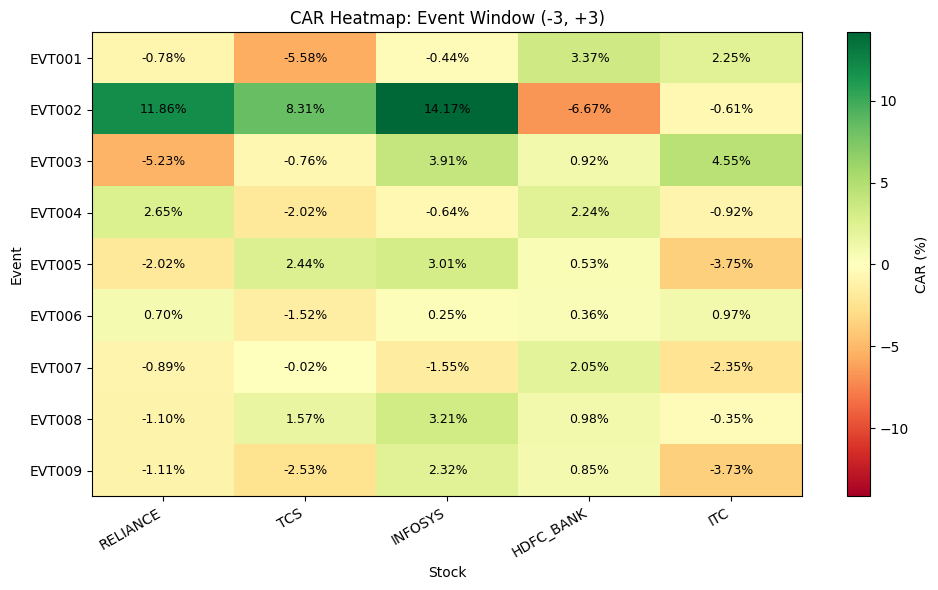

In [56]:
# Step 25.6: Heatmap of 7-session CAR across events and stocks

import matplotlib.pyplot as plt
import numpy as np

car_7day = multi_stock_car[
    multi_stock_car["window"] == "CAR_-3_+3"
].pivot(
    index="event_id",
    columns="stock",
    values="CAR_pct"
)

# Keep a consistent stock order
stock_order = ["RELIANCE", "TCS", "INFOSYS", "HDFC_BANK", "ITC"]
car_7day = car_7day[stock_order]

fig, ax = plt.subplots(figsize=(10, 6))

values = car_7day.to_numpy()
image = ax.imshow(values, aspect="auto", cmap="RdYlGn",
                  vmin=-np.abs(values).max(),
                  vmax=np.abs(values).max())

ax.set_xticks(range(len(car_7day.columns)))
ax.set_xticklabels(car_7day.columns, rotation=30, ha="right")
ax.set_yticks(range(len(car_7day.index)))
ax.set_yticklabels(car_7day.index)

for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        ax.text(j, i, f"{values[i, j]:.2f}%",
                ha="center", va="center", fontsize=9)

ax.set_title("CAR Heatmap: Event Window (-3, +3)")
ax.set_xlabel("Stock")
ax.set_ylabel("Event")
fig.colorbar(image, ax=ax, label="CAR (%)")
plt.tight_layout()
plt.show()

### Step 25.7: Statistical Significance of Multi-Stock CAR

Estimate the uncertainty of each stock's cumulative abnormal return using the residual variance from its corresponding market model. Calculate approximate t-statistics and p-values for the (−1, +1), (−3, +3), and (−5, +5) event windows.

Because multiple stocks, events, and windows are tested, raw p-values may overstate the evidence. Apply the Holm correction across the full family of tests. These tests are approximate and may not fully account for serial dependence, event-induced volatility, or overlapping economic developments.

In [57]:
# Step 25.7: Approximate CAR significance with Holm correction

from scipy import stats
from statsmodels.stats.multitest import multipletests

significance_rows = []

window_specs = [
    ("CAR_-1_+1", -1, 1),
    ("CAR_-3_+3", -3, 3),
    ("CAR_-5_+5", -5, 5)
]

for (event_id, stock), group in multi_stock_event_study.groupby(
    ["event_id", "stock"]
):
    model = multi_stock_models[(event_id, stock)]["model"]
    residual_std = np.sqrt(model.mse_resid)
    degrees_freedom = int(model.df_resid)

    for window_name, lower, upper in window_specs:
        selected = group[
            group["event_day"].between(lower, upper)
        ]

        n_sessions = len(selected)
        car = selected["abnormal_return"].sum()

        # Approximate standard error assuming independent residuals
        car_se = residual_std * np.sqrt(n_sessions)

        t_stat = car / car_se if car_se > 0 else np.nan
        p_value = (
            2 * stats.t.sf(abs(t_stat), df=degrees_freedom)
            if pd.notna(t_stat) else np.nan
        )

        significance_rows.append({
            "event_id": event_id,
            "stock": stock,
            "window": window_name,
            "CAR_pct": car * 100,
            "standard_error_pct": car_se * 100,
            "t_statistic": t_stat,
            "raw_p_value": p_value
        })

multi_car_significance = pd.DataFrame(significance_rows)

valid = multi_car_significance["raw_p_value"].notna()

multi_car_significance["holm_p_value"] = np.nan
multi_car_significance.loc[valid, "holm_p_value"] = multipletests(
    multi_car_significance.loc[valid, "raw_p_value"],
    method="holm"
)[1]

multi_car_significance["significant_5pct"] = (
    multi_car_significance["holm_p_value"] < 0.05
)

print("Tests evaluated:", len(multi_car_significance))
print("Significant after Holm correction:",
      int(multi_car_significance["significant_5pct"].sum()))

display(
    multi_car_significance[
        multi_car_significance["event_id"] == "EVT002"
    ].sort_values(["stock", "window"]).round(4)
)

Tests evaluated: 135
Significant after Holm correction: 4


,event_id,stock,window,CAR_pct,standard_error_pct,t_statistic,raw_p_value,holm_p_value,significant_5pct
15,EVT002,HDFC_BANK,CAR_-1_+1,4.2413,1.4372,2.9511,0.0040,0.5150,False
16,EVT002,HDFC_BANK,CAR_-3_+3,-6.6725,2.1953,-3.0394,0.0030,0.3982,False
17,EVT002,HDFC_BANK,CAR_-5_+5,-6.8808,2.7520,-2.5003,0.0141,1.0000,False
18,EVT002,INFOSYS,CAR_-1_+1,10.5853,3.6266,2.9188,0.0044,0.5623,False
19,EVT002,INFOSYS,CAR_-3_+3,14.1715,5.5397,2.5581,0.0121,1.0000,False
20,EVT002,INFOSYS,CAR_-5_+5,15.2380,6.9444,2.1943,0.0306,1.0000,False
21,EVT002,ITC,CAR_-1_+1,-13.6744,2.4756,-5.5237,0.0000,0.0000,True
22,EVT002,ITC,CAR_-3_+3,-0.6079,3.7815,-0.1608,0.8726,1.0000,False
23,EVT002,ITC,CAR_-5_+5,23.5467,4.7404,4.9673,0.0000,0.0004,True
24,EVT002,RELIANCE,CAR_-1_+1,5.4180,2.0872,2.5958,0.0109,1.0000,False


### Step 25.8: Cross-Stock Reaction Consistency

For each event and event window, compare abnormal returns across the five selected stocks. Calculate the cross-stock mean and median CAR, cross-stock standard deviation, and the proportion of stocks with positive CAR.

These statistics describe the direction and dispersion of observed stock reactions. They are descriptive measures, not evidence that an event caused the observed returns. The five-stock sample is small and does not represent the entire market.

In [60]:
print("Columns:")
print(multi_stock_car.columns.tolist())

print("\nFirst 5 rows:")
display(multi_stock_car.head())

Columns:
['event_id', 'stock', 'window', 'sessions', 'CAR_pct']

First 5 rows:


,event_id,stock,window,sessions,CAR_pct
0,EVT001,HDFC_BANK,CAR_-1_+1,3,1.920661
1,EVT001,HDFC_BANK,CAR_-3_+3,7,3.371338
2,EVT001,HDFC_BANK,CAR_-5_+5,11,2.490074
3,EVT001,INFOSYS,CAR_-1_+1,3,-3.616574
4,EVT001,INFOSYS,CAR_-3_+3,7,-0.441967


In [61]:
# Cross-stock reaction consistency

consistency_rows = []

for event_id in multi_stock_car["event_id"].unique():
    for window in ["CAR_-1_+1", "CAR_-3_+3", "CAR_-5_+5"]:

        values = multi_stock_car.loc[
            (multi_stock_car["event_id"] == event_id) &
            (multi_stock_car["window"] == window),
            "CAR_pct"
        ].dropna()

        consistency_rows.append({
            "event_id": event_id,
            "window": window,
            "mean_CAR_pct": values.mean(),
            "median_CAR_pct": values.median(),
            "cross_stock_std_pct": values.std(ddof=1),
            "positive_stock_fraction": (values > 0).mean(),
            "negative_stock_fraction": (values < 0).mean(),
            "stocks_observed": len(values)
        })

cross_stock_consistency = pd.DataFrame(consistency_rows)

display(cross_stock_consistency.round(3))

print("Total event-window summaries:",
      len(cross_stock_consistency))

print("\nCOVID event (EVT002):")

display(
    cross_stock_consistency[
        cross_stock_consistency["event_id"] == "EVT002"
    ].round(3)
)

,event_id,window,mean_CAR_pct,median_CAR_pct,cross_stock_std_pct,positive_stock_fraction,negative_stock_fraction,stocks_observed
0,EVT001,CAR_-1_+1,-1.773,-2.554,2.960,0.4,0.6,5
1,EVT001,CAR_-3_+3,-0.235,-0.442,3.465,0.4,0.6,5
2,EVT001,CAR_-5_+5,-0.724,-0.055,2.892,0.4,0.6,5
3,EVT002,CAR_-1_+1,1.843,4.241,9.171,0.8,0.2,5
4,EVT002,CAR_-3_+3,5.412,8.306,8.789,0.6,0.4,5
5,EVT002,CAR_-5_+5,10.954,15.238,11.664,0.8,0.2,5
6,EVT003,CAR_-1_+1,0.671,0.568,2.251,0.8,0.2,5
7,EVT003,CAR_-3_+3,0.677,0.923,3.951,0.6,0.4,5
8,EVT003,CAR_-5_+5,0.069,0.317,3.477,0.6,0.4,5
9,EVT004,CAR_-1_+1,0.105,0.312,1.140,0.6,0.4,5


Total event-window summaries: 27

COVID event (EVT002):


,event_id,window,mean_CAR_pct,median_CAR_pct,cross_stock_std_pct,positive_stock_fraction,negative_stock_fraction,stocks_observed
3,EVT002,CAR_-1_+1,1.843,4.241,9.171,0.8,0.2,5
4,EVT002,CAR_-3_+3,5.412,8.306,8.789,0.6,0.4,5
5,EVT002,CAR_-5_+5,10.954,15.238,11.664,0.8,0.2,5


### Step 25.9: Stock-Level CAR Dispersion Across Events

Visualize cumulative abnormal returns for individual stocks across the nine selected events using the (−3, +3) event window. A stock-level comparison helps identify whether an event is associated with broadly aligned reactions or substantial cross-stock dispersion.

The chart is descriptive. Differences may reflect company-specific exposures, sector characteristics, overlapping news, and estimation noise—not necessarily the causal effect of the event.

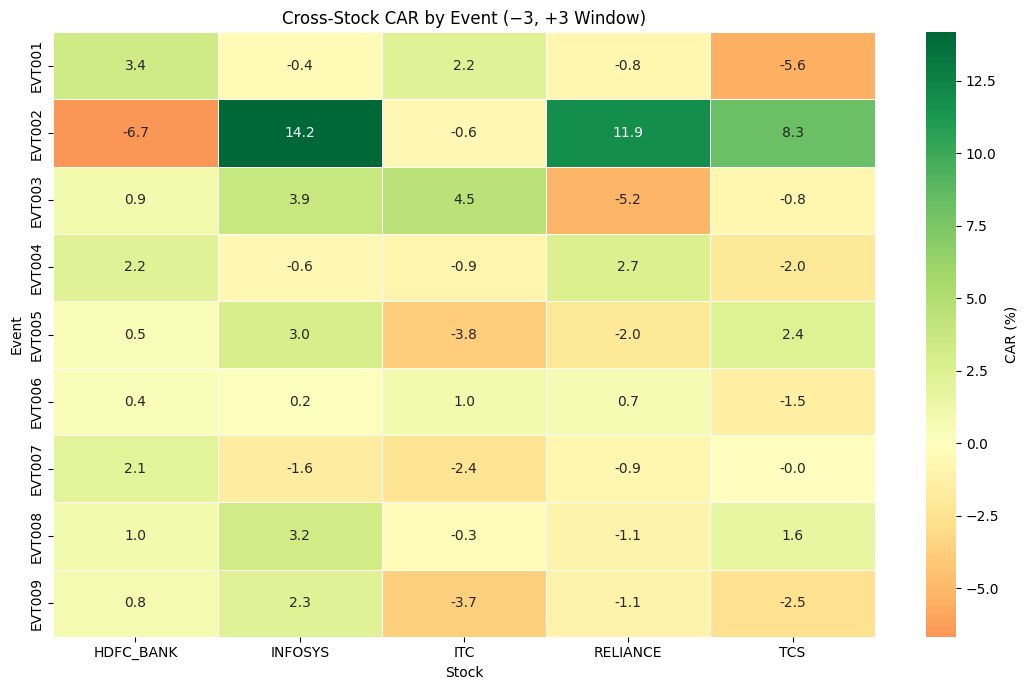

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = multi_stock_car[
    multi_stock_car["window"] == "CAR_-3_+3"
].pivot(
    index="event_id",
    columns="stock",
    values="CAR_pct"
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    plot_data,
    annot=True,
    fmt=".1f",
    center=0,
    cmap="RdYlGn",
    linewidths=0.5,
    cbar_kws={"label": "CAR (%)"}
)

plt.title("Cross-Stock CAR by Event (−3, +3 Window)")
plt.xlabel("Stock")
plt.ylabel("Event")
plt.tight_layout()
plt.show()

### Step 25.10: Prepare an Out-of-Sample Event Split

Separate the selected events chronologically into earlier events and later events. The earlier events form the development sample, while the later events are reserved for out-of-sample evaluation.

Because the dataset contains only nine manually selected events, this split is exploratory and cannot establish reliable generalization by itself. Any event-window or model choices should be fixed using the development sample before evaluating the holdout events.

In [63]:
# Step 25.10: Inspect chronological event sample

event_dates = expanded_events.copy()

display(
    event_dates[
        ["event_id", "event_date"]
    ].sort_values("event_date").reset_index(drop=True)
)

print("Total events:", len(event_dates))

,event_id,event_date
0,EVT001,2016-11-08
1,EVT002,2020-03-24
2,EVT003,2022-05-04
3,EVT004,2022-06-08
4,EVT005,2022-08-05
5,EVT007,2023-02-08
6,EVT008,2023-10-06
7,EVT009,2024-10-09
8,EVT006,2025-02-01


Total events: 9


### Step 25.11: Chronological Development and Holdout Split

Sort events by their effective event date. Use the earliest six events as the development sample and reserve the latest three events for holdout evaluation.

This chronological split prevents later events from informing the initial analysis. However, the small sample size and the presence of related monetary-policy events limit the strength of any generalization claims. The holdout sample should be evaluated only after the analysis choices are fixed.

In [64]:
# Chronological split: 6 development events, 3 holdout events

event_dates = expanded_events.copy()
event_dates["event_date"] = pd.to_datetime(event_dates["event_date"])

event_dates = event_dates.sort_values("event_date").reset_index(drop=True)

development_events = event_dates.iloc[:6].copy()
holdout_events = event_dates.iloc[6:].copy()

development_ids = development_events["event_id"].tolist()
holdout_ids = holdout_events["event_id"].tolist()

print("DEVELOPMENT EVENTS")
display(development_events[["event_id", "event_date"]])

print("\nHOLDOUT EVENTS")
display(holdout_events[["event_id", "event_date"]])

print("\nDevelopment count:", len(development_ids))
print("Holdout count:", len(holdout_ids))

DEVELOPMENT EVENTS


,event_id,event_date
0,EVT001,2016-11-08
1,EVT002,2020-03-24
2,EVT003,2022-05-04
3,EVT004,2022-06-08
4,EVT005,2022-08-05
5,EVT007,2023-02-08



HOLDOUT EVENTS


,event_id,event_date
6,EVT008,2023-10-06
7,EVT009,2024-10-09
8,EVT006,2025-02-01



Development count: 6
Holdout count: 3


### Step 25.12: Evaluate CAR Patterns on Holdout Events

Evaluate the cumulative abnormal returns of the three chronologically held-out events using the previously computed multi-stock CAR estimates.

Compare the mean CAR and proportion of positive stock reactions between the development and holdout samples for each event window. This is a descriptive generalization check, not a formal predictive test: the event sample is small, selected, and potentially heterogeneous.

In [65]:
# Step 25.12: Compare development vs holdout CAR patterns

window_order = ["CAR_-1_+1", "CAR_-3_+3", "CAR_-5_+5"]

car_eval = multi_stock_car.copy()

car_eval["sample"] = car_eval["event_id"].apply(
    lambda x: "Development" if x in development_ids
    else "Holdout" if x in holdout_ids
    else "Unassigned"
)

sample_summary = (
    car_eval[car_eval["sample"].isin(["Development", "Holdout"])]
    .groupby(["sample", "window"])
    .agg(
        mean_CAR_pct=("CAR_pct", "mean"),
        median_CAR_pct=("CAR_pct", "median"),
        positive_fraction=("CAR_pct", lambda x: (x > 0).mean()),
        event_stock_observations=("CAR_pct", "count")
    )
    .reset_index()
)

sample_summary["window"] = pd.Categorical(
    sample_summary["window"],
    categories=window_order,
    ordered=True
)

sample_summary = sample_summary.sort_values(
    ["window", "sample"]
).reset_index(drop=True)

display(sample_summary.round(3))

,sample,window,mean_CAR_pct,median_CAR_pct,positive_fraction,event_stock_observations
0,Development,CAR_-1_+1,0.239,0.579,0.667,30
1,Holdout,CAR_-1_+1,-0.266,-0.723,0.333,15
2,Development,CAR_-3_+3,0.934,-0.230,0.467,30
3,Holdout,CAR_-3_+3,0.058,0.360,0.600,15
4,Development,CAR_-5_+5,2.272,0.995,0.600,30
5,Holdout,CAR_-5_+5,-1.072,-1.053,0.333,15


### Step 25.13: Development vs Holdout Results

The development sample contains six events (30 stock-event observations), while the holdout sample contains three events (15 stock-event observations). Mean CAR, median CAR, and the fraction of positive stock reactions are compared across three event windows.

| Event Window | Sample | Mean CAR (%) | Median CAR (%) | Positive Fraction |
|---|---|---:|---:|---:|
| (−1, +1) | Development | 0.239 | 0.579 | 66.7% |
| (−1, +1) | Holdout | −0.266 | −0.723 | 33.3% |
| (−3, +3) | Development | 0.934 | −0.230 | 46.7% |
| (−3, +3) | Holdout | 0.058 | 0.360 | 60.0% |
| (−5, +5) | Development | 2.272 | 0.995 | 60.0% |
| (−5, +5) | Holdout | −1.072 | −1.053 | 33.3% |

**Interpretation**

- In the (−1, +1) window, the mean CAR changes from positive in the development sample to negative in the holdout sample.
- In the (−3, +3) window, the mean CAR remains slightly positive in both samples, although its magnitude decreases.
- In the (−5, +5) window, the mean CAR changes from +2.272% to −1.072%, indicating that the positive longer-window pattern does not persist in the holdout sample.
- The fraction of positive stock reactions also decreases from 60.0% to 33.3% in the (−5, +5) window.

**Conclusion**

The results provide limited evidence that average CAR patterns generalize consistently to later events. However, the holdout contains only three selected events, and individual stocks within the same event are not independent event observations. Therefore, these results are exploratory and do not establish predictive performance or a profitable trading strategy.

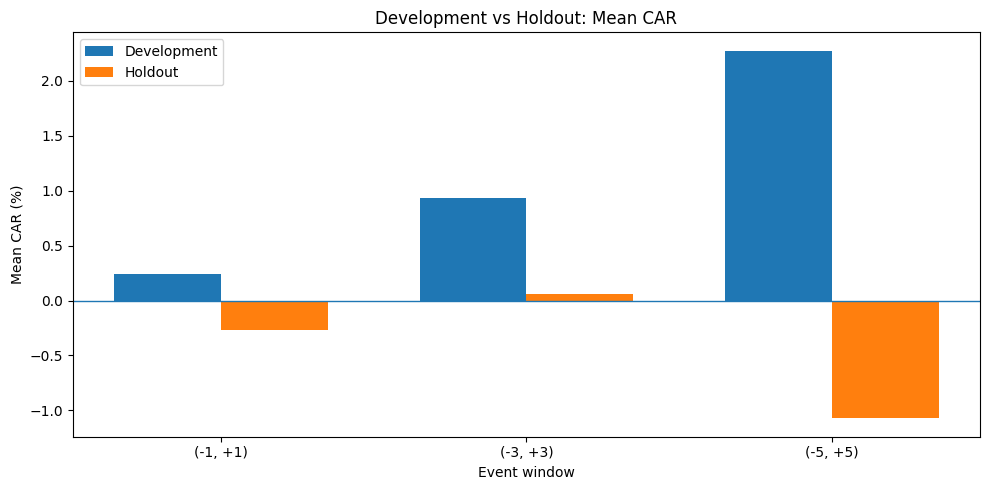

In [66]:
import matplotlib.pyplot as plt
import numpy as np

plot_summary = sample_summary.copy()

# Ensure the actual numeric columns are used
plot_summary["mean_CAR_pct"] = pd.to_numeric(
    plot_summary["mean_CAR_pct"]
)

windows = ["CAR_-1_+1", "CAR_-3_+3", "CAR_-5_+5"]
samples = ["Development", "Holdout"]

x = np.arange(len(windows))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

for i, sample in enumerate(samples):
    values = [
        plot_summary.loc[
            (plot_summary["sample"] == sample) &
            (plot_summary["window"] == window),
            "mean_CAR_pct"
        ].iloc[0]
        for window in windows
    ]

    ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=sample
    )

ax.axhline(0, linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(["(-1, +1)", "(-3, +3)", "(-5, +5)"])
ax.set_xlabel("Event window")
ax.set_ylabel("Mean CAR (%)")
ax.set_title("Development vs Holdout: Mean CAR")
ax.legend()
plt.tight_layout()
plt.show()

## Step 25.14: Multi-Stock Event Study — Final Findings

### 1. Multi-Stock Coverage

The analysis evaluated five stocks across nine selected events, producing 45 stock-event combinations. Abnormal returns were estimated using a market model with a 100-session estimation window, a 20-session gap, and event windows ranging from (−1, +1) to (−5, +5).

### 2. Cross-Stock Heterogeneity

Stock reactions differed across events and event windows. During the COVID-19 lockdown announcement period (EVT002), the mean CAR across the five stocks was approximately +1.84% for (−1, +1), +5.41% for (−3, +3), and +10.95% for (−5, +5). The corresponding cross-stock standard deviations were substantial, indicating that the average did not represent a uniform reaction across companies.

### 3. Statistical Significance

Approximate CAR significance tests were conducted across 135 stock-event-window combinations, followed by Holm correction for multiple testing. Four tests passed the 5% adjusted significance threshold. These findings are exploratory because the approximate standard errors do not fully account for parameter uncertainty, serial dependence, or event-induced volatility.

### 4. Robustness and Confounding

The analysis examined alternative event-window lengths, market-model sensitivity, extreme market sessions, and potentially confounding developments. The COVID-19 period illustrates why abnormal returns should not automatically be interpreted as causal effects of a single announcement.

### 5. Out-of-Sample Evaluation

A chronological split used six events for development and three later events for holdout evaluation. The mean CAR in the (−5, +5) window changed from +2.272% in the development sample to −1.072% in the holdout sample. This suggests that the positive longer-window pattern did not consistently persist in the later sample.

### 6. Limitations

- Only nine manually selected events were analyzed.
- Five stocks cannot represent the full market or their entire sectors.
- Some events may be related or accompanied by overlapping announcements.
- The Nifty 50 price index was used as the market benchmark; it does not include reinvested dividends.
- The holdout sample contains only three events and is too small to establish reliable predictive performance.
- Statistical significance does not establish causality or profitability after transaction costs.

### Overall Conclusion

The platform demonstrates a quantitative workflow for measuring abnormal returns, comparing event windows and stocks, evaluating approximate statistical significance, examining confounding developments, and testing whether historical patterns persist in later events.

The results show that observed reactions can vary substantially across stocks and event windows. The current analysis is best treated as an exploratory event-study framework rather than a validated trading strategy.

## Step 26.1: Define a Transaction-Cost-Aware Trading Hypothesis

Historical event-study results identify abnormal returns around selected announcements, but abnormal returns alone do not establish a tradable strategy.

This phase defines an explicit event-driven trading hypothesis and evaluates it using subsequent stock returns. The strategy rules must be specified before examining the holdout results.

**Initial hypothesis:** After an event announcement, a stock may exhibit a measurable directional reaction over a predefined holding period.

**Evaluation principles**
- Use only information available at the assumed entry time.
- Define entry and exit timing explicitly to avoid look-ahead bias.
- Include transaction costs and compare strategy returns with a suitable benchmark.
- Report the number of trades, average net return, volatility, drawdown, and uncertainty.
- Treat the nine-event dataset as exploratory; it is insufficient for a reliable profitability claim.

In [67]:
# Step 26.1: Inspect available price and event data

print("Available return columns:")
print(multi_returns.columns.tolist())

print("\nAvailable price columns:")
print(multi_stock_prices.columns.tolist())

print("\nEvent master columns:")
print(expanded_events.columns.tolist())

print("\nSample event dates:")
display(
    expanded_events[
        ["event_id", "event_date"]
    ].sort_values("event_date")
)

Available return columns:
['RELIANCE', 'TCS', 'INFOSYS', 'HDFC_BANK', 'ITC', 'NIFTY50_RETURN']

Available price columns:
['RELIANCE', 'TCS', 'INFOSYS', 'HDFC_BANK', 'ITC']

Event master columns:
['event_id', 'event_date', 'effective_event_date', 'event_time', 'headline', 'category', 'source_name', 'source_url', 'affected_stocks', 'episode_id', 'timing_confidence', 'overlap_flag', 'inclusion_reason', 'verification_status', 'notes']

Sample event dates:


,event_id,event_date
0,EVT001,2016-11-08
1,EVT002,2020-03-24
2,EVT003,2022-05-04
3,EVT004,2022-06-08
4,EVT005,2022-08-05
5,EVT007,2023-02-08
6,EVT008,2023-10-06
7,EVT009,2024-10-09
8,EVT006,2025-02-01


### Step 26.2: Define Entry, Exit, and Transaction Costs

Test a simple event-driven strategy using the five selected stocks.

**Trading rule**
- Event date is aligned using `effective_event_date`.
- Entry: close of the first available trading session strictly after the effective event date.
- Exit: close three trading sessions after entry.
- Position: initially long-only, with equal weighting across eligible stocks for each event.
- Transaction costs: apply a configurable cost in basis points to both entry and exit notional.
- Benchmark: compare net strategy returns with the Nifty 50 return over the same holding period.

This is an exploratory simulation. Closing-price execution may not be achievable without an explicit execution model. The event sample is small, and overlapping events must be considered before interpreting performance.

In [68]:
# Step 26.2: Build event-driven trade candidates

import numpy as np
import pandas as pd

stock_cols = ["RELIANCE", "TCS", "INFOSYS", "HDFC_BANK", "ITC"]
holding_sessions = 3

# Example cost assumption: 10 bps per side, configurable
cost_bps_per_side = 10
cost_per_side = cost_bps_per_side / 10000

prices = multi_stock_prices.copy()
prices.index = pd.to_datetime(prices.index)
prices = prices.sort_index()

market_returns = multi_returns.copy()
market_returns.index = pd.to_datetime(market_returns.index)
market_returns = market_returns.sort_index()

event_master = expanded_events.copy()
event_master["effective_event_date"] = pd.to_datetime(
    event_master["effective_event_date"]
)
event_master = event_master.sort_values("effective_event_date")

trade_rows = []

for _, event in event_master.iterrows():
    event_id = event["event_id"]
    event_date = event["effective_event_date"]

    # First trading session strictly after the effective event date
    future_dates = prices.index[prices.index > event_date]

    if len(future_dates) <= holding_sessions:
        continue

    entry_date = future_dates[0]
    exit_date = future_dates[holding_sessions]

    for stock in stock_cols:
        entry_price = prices.loc[entry_date, stock]
        exit_price = prices.loc[exit_date, stock]

        if (
            pd.isna(entry_price) or pd.isna(exit_price)
            or entry_price <= 0
        ):
            continue

        gross_return = exit_price / entry_price - 1

        # Approximate round-trip cost on notional
        net_return = gross_return - 2 * cost_per_side

        # Benchmark return over the same dates
        benchmark_slice = market_returns.loc[
            (market_returns.index > entry_date) &
            (market_returns.index <= exit_date),
            "NIFTY50_RETURN"
        ].dropna()

        benchmark_return = (
            (1 + benchmark_slice).prod() - 1
            if len(benchmark_slice) == holding_sessions
            else np.nan
        )

        trade_rows.append({
            "event_id": event_id,
            "effective_event_date": event_date,
            "stock": stock,
            "entry_date": entry_date,
            "exit_date": exit_date,
            "entry_price": entry_price,
            "exit_price": exit_price,
            "gross_return_pct": gross_return * 100,
            "net_return_pct": net_return * 100,
            "benchmark_return_pct": (
                benchmark_return * 100
                if pd.notna(benchmark_return) else np.nan
            ),
            "net_excess_return_pct": (
                (net_return - benchmark_return) * 100
                if pd.notna(benchmark_return) else np.nan
            )
        })

trade_candidates = pd.DataFrame(trade_rows)

print("Trade candidates:", len(trade_candidates))
print("Events represented:", trade_candidates["event_id"].nunique())

display(trade_candidates.head(10).round(4))

Trade candidates: 45
Events represented: 9


,event_id,effective_event_date,stock,entry_date,exit_date,entry_price,exit_price,gross_return_pct,net_return_pct,benchmark_return_pct,net_excess_return_pct
0,EVT001,2016-11-09,RELIANCE,2016-11-10,2016-11-16,220.3835,215.1815,-2.3604,-2.5604,-4.8576,2.2972
1,EVT001,2016-11-09,TCS,2016-11-10,2016-11-16,845.1947,858.5856,1.5844,1.3844,-4.8576,6.2420
2,EVT001,2016-11-09,INFOSYS,2016-11-10,2016-11-16,358.8369,359.4098,0.1597,-0.0403,-4.8576,4.8173
3,EVT001,2016-11-09,HDFC_BANK,2016-11-10,2016-11-16,291.5186,283.7208,-2.6749,-2.8749,-4.8576,1.9827
4,EVT001,2016-11-09,ITC,2016-11-10,2016-11-16,168.4630,154.9417,-8.0263,-8.2263,-4.8576,-3.3686
5,EVT002,2020-03-25,RELIANCE,2020-03-26,2020-03-31,474.7727,495.9465,4.4598,4.2598,-0.5057,4.7655
6,EVT002,2020-03-25,TCS,2020-03-26,2020-03-31,1519.3674,1549.1869,1.9626,1.7626,-0.5057,2.2683
7,EVT002,2020-03-25,INFOSYS,2020-03-26,2020-03-31,540.8062,539.5446,-0.2333,-0.4333,-0.5057,0.0724
8,EVT002,2020-03-25,HDFC_BANK,2020-03-26,2020-03-31,419.8066,401.5440,-4.3502,-4.5502,-0.5057,-4.0445
9,EVT002,2020-03-25,ITC,2020-03-26,2020-03-31,110.8769,121.7235,9.7826,9.5826,-0.5057,10.0883


### Step 26.3: Evaluate Event-Level Strategy Performance

Aggregate the five stock trades into an equal-weighted portfolio return for each event. Compare the portfolio's average net return with the Nifty 50 benchmark over the same holding period.

Report the average net return, median net return, win rate, return dispersion, average benchmark return, and average excess return.

The event—not each individual stock trade—is the primary unit for summary statistics. With only nine selected events, these metrics are descriptive and highly uncertain. They do not establish that the strategy is profitable or suitable for live trading.

In [69]:
# Step 26.3: Event-level performance evaluation

event_performance = (
    trade_candidates
    .groupby("event_id")
    .agg(
        portfolio_net_return_pct=("net_return_pct", "mean"),
        benchmark_return_pct=("benchmark_return_pct", "first"),
        portfolio_excess_return_pct=("net_excess_return_pct", "mean"),
        stocks_traded=("stock", "nunique")
    )
    .reset_index()
)

event_performance["portfolio_win"] = (
    event_performance["portfolio_net_return_pct"] > 0
)

display(event_performance.round(3))

# Summary across events, not across individual stock trades
summary_metrics = pd.DataFrame({
    "Metric": [
        "Number of events",
        "Average net portfolio return (%)",
        "Median net portfolio return (%)",
        "Event-level win rate (%)",
        "Standard deviation of event returns (%)",
        "Average benchmark return (%)",
        "Average excess return vs benchmark (%)",
        "Events outperforming benchmark (%)"
    ],
    "Value": [
        event_performance["event_id"].nunique(),
        event_performance["portfolio_net_return_pct"].mean(),
        event_performance["portfolio_net_return_pct"].median(),
        event_performance["portfolio_win"].mean() * 100,
        event_performance["portfolio_net_return_pct"].std(ddof=1),
        event_performance["benchmark_return_pct"].mean(),
        event_performance["portfolio_excess_return_pct"].mean(),
        (
            event_performance["portfolio_excess_return_pct"] > 0
        ).mean() * 100
    ]
})

display(summary_metrics.round(3))

,event_id,portfolio_net_return_pct,benchmark_return_pct,portfolio_excess_return_pct,stocks_traded,portfolio_win
0,EVT001,-2.464,-4.858,2.394,5,False
1,EVT002,2.124,-0.506,2.630,5,True
2,EVT003,-2.641,-2.653,0.012,5,False
3,EVT004,-5.019,-4.527,-0.491,5,False
4,EVT005,0.183,0.987,-0.804,5,True
5,EVT006,1.205,1.037,0.168,5,True
6,EVT007,0.396,0.203,0.192,5,True
7,EVT008,0.492,1.443,-0.951,5,True
8,EVT009,-0.172,0.236,-0.408,5,False


,Metric,Value
0,Number of events,9.000
1,Average net portfolio return (%),-0.655
2,Median net portfolio return (%),0.183
3,Event-level win rate (%),55.556
4,Standard deviation of event returns (%),2.258
5,Average benchmark return (%),-0.960
6,Average excess return vs benchmark (%),0.305
7,Events outperforming benchmark (%),55.556


### Step 26.5: Transaction-Cost Sensitivity

Recalculate the equal-weighted portfolio performance under several assumed transaction costs: 0, 5, 10, 20, and 30 basis points per side.

For each cost level, calculate the average event-level net return, median return, event win rate, average excess return versus the Nifty 50, and benchmark outperformance rate.

This is a sensitivity analysis, not a backtest of executable live orders. It excludes slippage beyond the specified cost assumption, taxes and other market frictions unless captured by the assumed costs.

,cost_bps_per_side,avg_net_return_pct,median_net_return_pct,event_win_rate_pct,avg_excess_return_pct,benchmark_outperformance_rate_pct
0,0,-0.455,0.383,66.667,0.505,55.556
1,5,-0.555,0.283,55.556,0.405,55.556
2,10,-0.655,0.183,55.556,0.305,55.556
3,20,-0.855,-0.017,44.444,0.105,22.222
4,30,-1.055,-0.217,33.333,-0.095,22.222


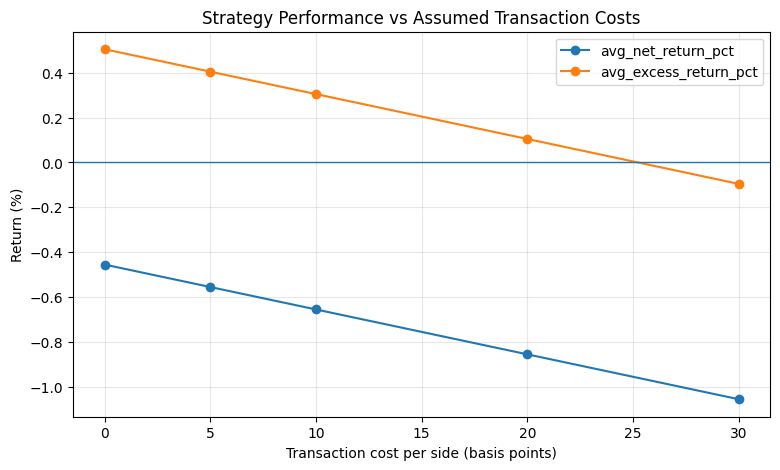

In [70]:
# Step 26.5: Transaction-cost sensitivity

cost_levels_bps = [0, 5, 10, 20, 30]
sensitivity_rows = []

for cost_bps in cost_levels_bps:
    # gross_return_pct is already in percentage units.
    # Two sides: entry + exit.
    round_trip_cost_pct = 2 * cost_bps / 100

    temp = trade_candidates.copy()
    temp["net_return_at_cost_pct"] = (
        temp["gross_return_pct"] - round_trip_cost_pct
    )

    event_results = (
        temp.groupby("event_id")
        .agg(
            portfolio_net_return_pct=("net_return_at_cost_pct", "mean"),
            benchmark_return_pct=("benchmark_return_pct", "first")
        )
        .reset_index()
    )

    event_results["excess_return_pct"] = (
        event_results["portfolio_net_return_pct"]
        - event_results["benchmark_return_pct"]
    )

    sensitivity_rows.append({
        "cost_bps_per_side": cost_bps,
        "avg_net_return_pct":
            event_results["portfolio_net_return_pct"].mean(),
        "median_net_return_pct":
            event_results["portfolio_net_return_pct"].median(),
        "event_win_rate_pct":
            (event_results["portfolio_net_return_pct"] > 0).mean() * 100,
        "avg_excess_return_pct":
            event_results["excess_return_pct"].mean(),
        "benchmark_outperformance_rate_pct":
            (event_results["excess_return_pct"] > 0).mean() * 100
    })

cost_sensitivity = pd.DataFrame(sensitivity_rows)

display(cost_sensitivity.round(3))

# Visualize average net return and average excess return
ax = cost_sensitivity.plot(
    x="cost_bps_per_side",
    y=["avg_net_return_pct", "avg_excess_return_pct"],
    marker="o",
    figsize=(9, 5),
    title="Strategy Performance vs Assumed Transaction Costs"
)

ax.set_xlabel("Transaction cost per side (basis points)")
ax.set_ylabel("Return (%)")
ax.axhline(0, linewidth=1)
ax.grid(True, alpha=0.3)

In [71]:
# Step 26.6: Final strategy assessment

baseline = cost_sensitivity.loc[
    cost_sensitivity["cost_bps_per_side"] == 10
].iloc[0]

highest_cost = cost_sensitivity.loc[
    cost_sensitivity["cost_bps_per_side"] == 30
].iloc[0]

assessment = pd.DataFrame({
    "Finding": [
        "Number of events",
        "Baseline cost per side (bps)",
        "Baseline average net return (%)",
        "Baseline average excess return (%)",
        "Baseline event win rate (%)",
        "Average excess return at 30 bps per side (%)",
        "Benchmark outperformance rate at baseline (%)"
    ],
    "Value": [
        event_performance["event_id"].nunique(),
        10,
        baseline["avg_net_return_pct"],
        baseline["avg_excess_return_pct"],
        baseline["event_win_rate_pct"],
        highest_cost["avg_excess_return_pct"],
        baseline["benchmark_outperformance_rate_pct"]
    ]
})

display(assessment.round(3))

,Finding,Value
0,Number of events,9.000
1,Baseline cost per side (bps),10.000
2,Baseline average net return (%),-0.655
3,Baseline average excess return (%),0.305
4,Baseline event win rate (%),55.556
5,Average excess return at 30 bps per side (%),-0.095
6,Benchmark outperformance rate at baseline (%),55.556


### Step 27: Out-of-Sample Trading Evaluation

Evaluate the fixed event-driven trading strategy separately on development and holdout events.

**Predefined strategy**
- Entry: close of the first available trading session after the effective event date.
- Exit: close three trading sessions after entry.
- Universe: Reliance Industries, TCS, Infosys, HDFC Bank, and ITC.
- Portfolio: equal-weighted across available stock trades per event.
- Transaction cost: 10 basis points per side.
- Benchmark: Nifty 50 over the same holding period.

The first six chronological events form the development sample; the final three form the holdout sample. The holdout results are used only for evaluation, not to tune the strategy.

Because the sample contains only nine selected events, the results are exploratory and cannot establish reliable future profitability.

Events by sample:


,sample,number_of_events
0,Development,6
1,Holdout,3


,event_id,portfolio_net_return_pct,benchmark_return_pct,stocks_traded,excess_return_pct,sample
0,EVT001,-2.464,-4.858,5,2.394,Development
1,EVT002,2.124,-0.506,5,2.630,Development
2,EVT003,-2.641,-2.653,5,0.012,Development
3,EVT004,-5.019,-4.527,5,-0.491,Development
4,EVT005,0.183,0.987,5,-0.804,Development
5,EVT006,1.205,1.037,5,0.168,Holdout
6,EVT007,0.396,0.203,5,0.192,Development
7,EVT008,0.492,1.443,5,-0.951,Holdout
8,EVT009,-0.172,0.236,5,-0.408,Holdout


,sample,number_of_events,mean_net_return_pct,median_net_return_pct,event_win_rate_pct,mean_benchmark_return_pct,mean_excess_return_pct,benchmark_outperformance_rate_pct
0,Development,6,-1.237,-1.140,50.000,-1.892,0.655,66.667
1,Holdout,3,0.508,0.492,66.667,0.905,-0.397,33.333


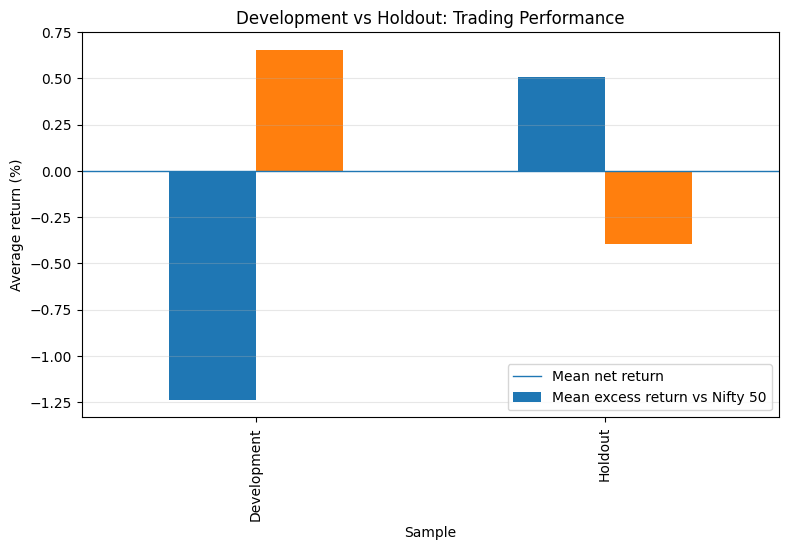

In [72]:
# Step 27: Out-of-sample trading evaluation

# Aggregate individual stock trades into event-level portfolios
event_trading_results = (
    trade_candidates
    .groupby("event_id")
    .agg(
        portfolio_net_return_pct=("net_return_pct", "mean"),
        benchmark_return_pct=("benchmark_return_pct", "first"),
        stocks_traded=("stock", "nunique")
    )
    .reset_index()
)

event_trading_results["excess_return_pct"] = (
    event_trading_results["portfolio_net_return_pct"]
    - event_trading_results["benchmark_return_pct"]
)

# Assign each event to the predefined sample
event_trading_results["sample"] = np.where(
    event_trading_results["event_id"].isin(development_ids),
    "Development",
    np.where(
        event_trading_results["event_id"].isin(holdout_ids),
        "Holdout",
        "Unassigned"
    )
)

# Check that all events are accounted for
print("Events by sample:")
display(
    event_trading_results.groupby("sample")["event_id"]
    .nunique()
    .rename("number_of_events")
    .reset_index()
)

# Show event-level results
display(
    event_trading_results
    .sort_values("event_id")
    .round(3)
)

# Compare samples; each event gets equal weight
sample_performance = (
    event_trading_results[event_trading_results["sample"] != "Unassigned"]
    .groupby("sample")
    .agg(
        number_of_events=("event_id", "nunique"),
        mean_net_return_pct=("portfolio_net_return_pct", "mean"),
        median_net_return_pct=("portfolio_net_return_pct", "median"),
        event_win_rate_pct=(
            "portfolio_net_return_pct",
            lambda x: (x > 0).mean() * 100
        ),
        mean_benchmark_return_pct=("benchmark_return_pct", "mean"),
        mean_excess_return_pct=("excess_return_pct", "mean"),
        benchmark_outperformance_rate_pct=(
            "excess_return_pct",
            lambda x: (x > 0).mean() * 100
        )
    )
    .reindex(["Development", "Holdout"])
    .reset_index()
)

display(sample_performance.round(3))

# Plot average net return and excess return
plot_data = sample_performance.set_index("sample")[
    ["mean_net_return_pct", "mean_excess_return_pct"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    title="Development vs Holdout: Trading Performance"
)

ax.set_xlabel("Sample")
ax.set_ylabel("Average return (%)")
ax.axhline(0, linewidth=1)
ax.legend(["Mean net return", "Mean excess return vs Nifty 50"])
ax.grid(axis="y", alpha=0.3)

### Out-of-Sample Trading Evaluation: Findings

The event-driven strategy was evaluated using six development events and three chronologically later holdout events. Entry, exit, portfolio weighting, and transaction-cost assumptions were fixed before evaluating the holdout sample.

The development sample produced an average net return of −1.237% and average excess return of +0.655 percentage points versus the Nifty 50. The holdout sample produced an average net return of +0.508%, but an average excess return of −0.397 percentage points.

These results do not demonstrate consistent benchmark outperformance out of sample. The small number of selected events, event-specific market conditions, equal-weighted portfolio construction, and simplified transaction-cost assumptions limit the conclusions. The strategy should be treated as an exploratory research hypothesis rather than a validated trading system.

## Step 28: Final Research Artifacts and Reproducibility

Export the core EventEcho outputs into clean CSV files so the analysis can be inspected independently of the notebook.

Artifacts include:
- Event master and verification metadata
- Single-stock event-study results
- Multi-stock cumulative abnormal returns
- Statistical significance results
- Cross-stock consistency results
- Event-level trading simulation results
- Development-versus-holdout performance
- Transaction-cost sensitivity analysis

These files support reproducibility and make the project easier to review on GitHub. Results remain exploratory because the event sample is small and selected.

In [73]:
# Step 28.1: Export final EventEcho research artifacts

from pathlib import Path
import zipfile
import json
import pandas as pd
from datetime import datetime, timezone

output_dir = Path("/kaggle/working/EventEcho_artifacts")
output_dir.mkdir(parents=True, exist_ok=True)

# Core artifacts available from the completed analysis
artifacts = {
    "event_master.csv": expanded_events,
    "multi_stock_event_study.csv": multi_stock_event_study,
    "multi_stock_car.csv": multi_stock_car,
    "cross_stock_consistency.csv": cross_stock_consistency,
    "trade_candidates.csv": trade_candidates,
    "event_trading_results.csv": event_trading_results,
    "sample_performance.csv": sample_performance,
    "transaction_cost_sensitivity.csv": cost_sensitivity,
    "final_strategy_assessment.csv": assessment,
}

# Export significance results if the dataframe exists
if "multi_car_significance" in globals():
    artifacts["multi_stock_significance.csv"] = multi_car_significance

# Export the single-stock event-study results if available
for candidate in [
    "event_study",
    "event_study_results",
    "single_stock_event_study",
]:
    if candidate in globals() and isinstance(globals()[candidate], pd.DataFrame):
        artifacts["single_stock_event_study.csv"] = globals()[candidate]
        break

export_log = []

for filename, dataframe in artifacts.items():
    if isinstance(dataframe, pd.DataFrame):
        dataframe.to_csv(output_dir / filename, index=False)
        export_log.append({
            "file": filename,
            "rows": len(dataframe),
            "columns": len(dataframe.columns),
            "status": "exported"
        })

export_manifest = {
    "project": "EventEcho",
    "purpose": "Exploratory quantitative event study and trading simulation",
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "event_count": int(expanded_events["event_id"].nunique()),
    "stock_universe": ["RELIANCE", "TCS", "INFOSYS", "HDFC_BANK", "ITC"],
    "benchmark": "Nifty 50 (^NSEI) price index",
    "trading_holding_sessions": 3,
    "transaction_cost_bps_per_side": 10,
    "development_event_ids": list(development_ids),
    "holdout_event_ids": list(holdout_ids),
    "artifacts": export_log,
    "caveats": [
        "Selected event sample is small and not representative of all market events.",
        "Trading simulation is hypothetical and excludes detailed execution frictions.",
        "Nifty 50 benchmark uses a price index, not a total-return index.",
        "Statistical tests are exploratory and have methodological limitations."
    ]
}

with open(output_dir / "manifest.json", "w", encoding="utf-8") as f:
    json.dump(export_manifest, f, indent=2, default=str)

# Bundle everything into one ZIP
zip_path = Path("/kaggle/working/EventEcho_artifacts.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file_path in output_dir.iterdir():
        if file_path.is_file():
            zf.write(file_path, arcname=file_path.name)

print("Exported artifacts:")
display(pd.DataFrame(export_log))

print(f"\nArtifact folder: {output_dir}")
print(f"ZIP bundle: {zip_path}")

Exported artifacts:


,file,rows,columns,status
0,event_master.csv,9,15,exported
1,multi_stock_event_study.csv,495,8,exported
2,multi_stock_car.csv,135,5,exported
3,cross_stock_consistency.csv,27,8,exported
4,trade_candidates.csv,45,11,exported
5,event_trading_results.csv,9,6,exported
6,sample_performance.csv,2,8,exported
7,transaction_cost_sensitivity.csv,5,6,exported
8,final_strategy_assessment.csv,7,2,exported
9,multi_stock_significance.csv,135,9,exported



Artifact folder: /kaggle/working/EventEcho_artifacts
ZIP bundle: /kaggle/working/EventEcho_artifacts.zip
